### 🔴 Section 1: Implement for MA's

#### ⚪ 1. Libraries

In [1]:
### Cell 1 
import pandas as pd
import scipy.io
import numpy as np
import time
from scipy.io import loadmat
from sklearn.preprocessing import MinMaxScaler
from scipy.spatial.distance import cdist
from sklearn.metrics import roc_auc_score, average_precision_score

#### ⚪ 2. Extract indices from .csv file

In [2]:
### Cell 2
# --- Configuration ---
csv_file_path = '/media/mine/Mine/3.Main-Ubuntu-Envs/2.Thesis-Env/3.Datasets/mammographyori.csv'

def get_ma_indices(df, feature_name, low, high):
    condition = (df[feature_name] >= low) & (df[feature_name] <= high)
    subset = df[condition]
    indices = subset.index.to_numpy()
    counts = subset['label'].value_counts()
    return indices, counts

df_original = pd.read_csv(csv_file_path, header=None)
df_original.columns = ['c1', 'c2', 'c3', 'c4', 'c5', 'c6', 'label']
print(f"Shape of the original dataset: {df_original.shape} (rows, columns)")

ma_conditions = {
    'MA1': ('c4', -0.9, 2),
    'MA2': ('c5', -0.4, 1),
    'MA3': ('c6', -1, 1),
}

ma_indices = {}
ma_label_counts = {}
for name, (feature, low, high) in ma_conditions.items():
    indices, counts = get_ma_indices(df_original, feature, low, high)
    ma_indices[name] = indices
    ma_label_counts[name] = counts
    print(f"{name} Condition: Feature '{feature}' in [{low}, {high}]")
    print(f"  samples = {len(indices)}")
    print(f"  label counts =\n{counts}\n")

Shape of the original dataset: (11183, 7) (rows, columns)
MA1 Condition: Feature 'c4' in [-0.9, 2]
  samples = 10951
  label counts =
label
1    10747
2      204
Name: count, dtype: int64

MA2 Condition: Feature 'c5' in [-0.4, 1]
  samples = 10098
  label counts =
label
1    10022
2       76
Name: count, dtype: int64

MA3 Condition: Feature 'c6' in [-1, 1]
  samples = 8263
  label counts =
label
1    8209
2      54
Name: count, dtype: int64



#### ⚪ 3. Create X_tem lists for MA1/MA2/MA3

In [3]:
### Cell 3
X_tem_ma1 = ma_indices['MA1'].tolist()
X_tem_ma2 = ma_indices['MA2'].tolist()
X_tem_ma3 = ma_indices['MA3'].tolist()

print('MA1 size:', len(X_tem_ma1))
print('MA2 size:', len(X_tem_ma2))
print('MA3 size:', len(X_tem_ma3))

MA1 size: 10951
MA2 size: 10098
MA3 size: 8263


In [4]:
### Cell 4
# ==========================================
# 1. Baseline Implementation (Original)
# ==========================================
def WNCROD_original(data, X_tem, lammda):
    n, m = data.shape
    X = np.zeros(n)
    X[X_tem] = 1
    D1 = m / 3
    D2 = m / 2
    D3 = 0.9 * m
    delta = np.zeros(m)
    ID = np.all(data <= 1, axis=0)
    delta[ID] = np.std(data[:, ID], axis=0) / lammda
    Lower = np.zeros((m, n))

    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        Lower_temp = np.min(np.maximum(1 - RM_tem, np.tile(X, (n, 1))), axis=1)
        Lower[col, :Lower_temp.shape[0]] = Lower_temp

    IB = np.tile(X, (m, 1)) - Lower
    NEB = np.min(IB, axis=0)
    NPB = IB - np.tile(NEB, (m, 1))
    n_X = int(sum(X))
    weight = np.zeros((n_X, m))

    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        weight_x = []
        for i in range(n_X):
            temp1 = RM_tem[X_tem[i], :]
            weight_temp = 1 - (np.sqrt((np.sum(np.minimum(temp1, X))) / n_X))
            weight_x.append(weight_temp)
        weight[:len(weight_x), col] = weight_x
    D_tem = np.zeros((n, n))

    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        D_tem += RM_tem

    NOM = m - D_tem
    X_OM = NOM[np.ix_(X_tem, X_tem)]
    NEB_num = np.zeros((n_X, m))
    Lower_num = np.zeros((n_X, m))
    NPB_num = np.zeros((n_X, m))

    for col in range(m):
        temp2 = Lower[col, :]
        temp3 = NPB[col, :]
        for i in range(n_X):
            temp1 = X_OM[i, :]
            NEB_num[i, col] = np.sum(np.minimum(NEB[X_tem], temp1 <= D1))
            NPB_num[i, col] = np.sum(np.minimum(temp3[X_tem], temp1 >= D2))
            Lower_num[i, col] = np.sum(np.minimum(temp2[X_tem], temp1 >= D3))
    MNOF = np.mean(((NEB_num + Lower_num + NPB_num) / n_X) * weight, axis=1)
    return MNOF


# ==========================================
# 2. Optimized Implementation (Claude)
# ==========================================
def _neighbour_interval(x, s, rank, eps):
    k = x.size
    if not eps >= 0:
        z = np.zeros(k, dtype=np.intp)
        return z, z.copy()

    lo = np.zeros(k, dtype=np.intp)
    hi = rank.astype(np.intp, copy=True)
    while True:
        act = lo < hi
        if not act.any():
            break
        mid = (lo + hi) >> 1
        ok = np.abs(x - s[mid]) <= eps
        np.copyto(hi, mid, where=act & ok)
        np.copyto(lo, mid + 1, where=act & ~ok)
    left = lo

    lo = rank.astype(np.intp, copy=True)
    hi = np.full(k, k - 1, dtype=np.intp)
    while True:
        act = lo < hi
        if not act.any():
            break
        mid = (lo + hi + 1) >> 1
        ok = np.abs(x - s[mid]) <= eps
        np.copyto(lo, mid, where=act & ok)
        np.copyto(hi, mid - 1, where=act & ~ok)
    return left, lo + 1

def _has_outside_neighbour_sorted(x, out_vals, eps):
    res = np.zeros(x.size, dtype=bool)
    if out_vals.size == 0 or not eps >= 0:
        return res
    s = np.sort(out_vals)
    pos = np.searchsorted(s, x, side="left")
    up = np.minimum(pos, s.size - 1)
    dn = np.maximum(pos - 1, 0)
    np.logical_or((pos < s.size) & (np.abs(x - s[up]) <= eps),
                  (pos > 0) & (np.abs(x - s[dn]) <= eps), out=res)
    return res

def _has_outside_neighbour_dense(x, out_vals, eps, block):
    res = np.zeros(x.size, dtype=bool)
    if out_vals.size == 0:
        return res
    for start in range(0, x.size, block):
        stop = min(start + block, x.size)
        d = np.abs(x[start:stop, None] - out_vals[None, :])
        np.any(d <= eps, axis=1, out=res[start:stop])
    return res

def WNCROD_optimized(data, X_tem, lammda, block_size=None, sorted_kernel=True):
    data = np.asarray(data)
    if data.ndim != 2:
        raise ValueError("data must be a 2-D (samples x attributes) array")
    n, m = data.shape
    if m == 0:
        raise ValueError("data must have at least one attribute")

    X_tem = np.asarray(X_tem)
    if X_tem.dtype == np.bool_:
        X_idx = np.flatnonzero(X_tem)
    else:
        X_idx = np.ascontiguousarray(X_tem, dtype=np.intp).ravel()
    n_X = X_idx.size
    if n_X == 0:
        return np.zeros(0, dtype=np.float64)

    in_X = np.zeros(n, dtype=bool)
    in_X[X_idx] = True
    if int(np.count_nonzero(in_X)) != n_X:
        raise ValueError("X_tem must hold unique object indices")
    C_idx = np.flatnonzero(~in_X)

    D1, D2, D3 = m / 3, m / 2, 0.9 * m
    delta = np.zeros(m)
    ID = np.all(data <= 1, axis=0)
    if ID.any():
        delta[ID] = np.std(data[:, ID], axis=0) / lammda

    om = np.arange(m + 1)
    s1, s2, s3 = om <= D1, om >= D2, om >= D3
    k1 = m - int(om[s1].max()) if s1.any() else None
    k2 = m - int(om[s2].min()) if s2.any() else None
    k3 = m - int(om[s3].min()) if s3.any() else None

    work = np.ascontiguousarray(data, dtype=np.float64)
    if sorted_kernel and not np.isfinite(work).all():
        raise ValueError("sorted_kernel=True requires finite data; use sorted_kernel=False for NaN/inf input")
    VX = np.ascontiguousarray(work[X_idx].T)
    VC = np.ascontiguousarray(work[C_idx].T)
    del work

    if block_size is None:
        block_size = min(n_X, max(64, (1 << 21) // n_X))
    block_size = int(min(max(1, int(block_size)), n_X))

    POS = np.empty((m, n_X), dtype=bool)
    hit = np.empty((n_X, m), dtype=np.float64)
    if sorted_kernel:
        rank_all = np.empty((m, n_X), dtype=np.int32)
        lo_all = np.empty((m, n_X), dtype=np.int32)
        hi_all = np.empty((m, n_X), dtype=np.int32)
        iota = np.arange(n_X, dtype=np.intp)

    for j in range(m):
        v, eps = VX[j], delta[j]
        if sorted_kernel:
            order = np.argsort(v, kind="stable")
            s = v[order]
            rank = np.empty(n_X, dtype=np.intp)
            rank[order] = iota
            lo, hi = _neighbour_interval(v, s, rank, eps)
            rank_all[j] = rank
            lo_all[j] = lo
            hi_all[j] = hi
            hit[:, j] = hi - lo
            POS[j] = ~_has_outside_neighbour_sorted(v, VC[j], eps)
        else:
            POS[j] = ~_has_outside_neighbour_dense(v, VC[j], eps, block_size)

    NIB = ~POS
    NEB = NIB.all(axis=0)
    NPB = NIB & ~NEB
    del NIB

    gemm_dt = np.float32 if n_X < (1 << 24) else np.float64
    NPB_f = np.ascontiguousarray(NPB.T, dtype=gemm_dt)
    POS_f = np.ascontiguousarray(POS.T, dtype=gemm_dt)

    cnt_dt = np.uint8 if m <= 255 else (np.uint16 if m <= 65535 else np.uint32)
    cnt = np.empty((block_size, n_X), dtype=cnt_dt)
    buf1 = np.empty((block_size, n_X), dtype=bool)
    buf2 = np.empty((block_size, n_X), dtype=bool)
    fbuf = np.empty((block_size, n_X), dtype=gemm_dt)
    dbuf = None if sorted_kernel else np.empty((block_size, n_X), np.float64)

    neb_cnt = np.zeros(n_X, dtype=np.float64)
    npb_cnt = np.zeros((n_X, m), dtype=np.float64)
    pos_cnt = np.zeros((n_X, m), dtype=np.float64)

    for start in range(0, n_X, block_size):
        stop = min(start + block_size, n_X)
        b = stop - start
        c, a, t = cnt[:b], buf1[:b], buf2[:b]
        c.fill(0)

        for j in range(m):
            if sorted_kernel:
                r = rank_all[j]
                np.greater_equal(r, lo_all[j][start:stop, None], out=a)
                np.less(r, hi_all[j][start:stop, None], out=t)
                np.logical_and(a, t, out=a)
            else:
                v, d = VX[j], dbuf[:b]
                np.subtract(v[start:stop, None], v[None, :], out=d)
                np.abs(d, out=d)
                np.less_equal(d, delta[j], out=a)
                hit[start:stop, j] = np.count_nonzero(a, axis=1)
            c += a

        if k1 is not None:
            np.greater_equal(c, k1, out=a)
            np.logical_and(a, NEB, out=a)
            neb_cnt[start:stop] = np.count_nonzero(a, axis=1)
        if k2 is not None:
            np.less_equal(c, k2, out=a)
            np.copyto(fbuf[:b], a)
            npb_cnt[start:stop] = fbuf[:b] @ NPB_f
        if k3 is not None:
            np.less_equal(c, k3, out=a)
            np.copyto(fbuf[:b], a)
            pos_cnt[start:stop] = fbuf[:b] @ POS_f

    weight = 1 - np.sqrt(hit / n_X)
    ndf = neb_cnt[:, None] + pos_cnt + npb_cnt
    return np.mean((ndf / n_X) * weight, axis=1)

#### ⚪ 4. Run WNCROD for MA1, MA2, and MA3 for λ = 0.5

In [5]:
### Cell 5
# 1) Load data and normalize once
mat = loadmat('/media/mine/Mine/3.Main-Ubuntu-Envs/2.Thesis-Env/3.Datasets/mammography.mat')
full_data = mat['trandata']            # shape = (n_samples, 7)
X = full_data[:, :6]
y = full_data[:, 6].astype(int)
scaler = MinMaxScaler()
X[:, 1:] = scaler.fit_transform(X[:, 1:])
print('Loaded and normalized data once for all MA subsets.')

# Validation & Timing Test on MA3 (smallest subset for quick validation)
print("\n--- Validation & Speedup Test (on MA3, λ = 0.5) ---")
t0 = time.perf_counter()
scores_orig = WNCROD_original(X, X_tem_ma3, lammda=0.5)
t_orig = time.perf_counter() - t0

t0 = time.perf_counter()
scores_opt = WNCROD_optimized(X, X_tem_ma3, lammda=0.5)
t_opt = time.perf_counter() - t0

# Check equivalence
max_diff = np.max(np.abs(scores_orig - scores_opt))
is_identical = np.allclose(scores_orig, scores_opt, atol=1e-12)

print(f"Original Time:  {t_orig:.4f} s")
print(f"Optimized Time: {t_opt:.4f} s")
print(f"Speedup Factor: {t_orig / t_opt:.2f}x")
print(f"Max absolute difference: {max_diff}")
print(f"Are outputs bitwise close (atol=1e-12)? {is_identical}")

# Standard evaluation helper function (now using the optimized code)
def evaluate_wncrod(data, labels, X_tem, lam=0.5):
    out_scores = WNCROD_optimized(data, X_tem, lammda=lam)
    return roc_auc_score(labels[X_tem], out_scores), average_precision_score(labels[X_tem], out_scores)

print('\nRunning WNCROD_optimized for MA1, MA2, MA3 with λ = 0.5')
for name, X_tem in [('MA1', X_tem_ma1), ('MA2', X_tem_ma2), ('MA3', X_tem_ma3)]:
    t0 = time.perf_counter()
    roc_auc, ap = evaluate_wncrod(X, y, X_tem, lam=0.5)
    elapsed = time.perf_counter() - t0
    print(f"{name} ({len(X_tem)} samples): ROC-AUC = {roc_auc:.4f}, AP = {ap:.4f} [Time: {elapsed:.2f} s]")

Loaded and normalized data once for all MA subsets.

--- Validation & Speedup Test (on MA3, λ = 0.5) ---
Original Time:  79.8991 s
Optimized Time: 0.7801 s
Speedup Factor: 102.42x
Max absolute difference: 0.0
Are outputs bitwise close (atol=1e-12)? True

Running WNCROD_optimized for MA1, MA2, MA3 with λ = 0.5
MA1 (10951 samples): ROC-AUC = 0.8931, AP = 0.3550 [Time: 1.87 s]
MA2 (10098 samples): ROC-AUC = 0.7745, AP = 0.0626 [Time: 1.37 s]
MA3 (8263 samples): ROC-AUC = 0.7748, AP = 0.0827 [Time: 0.90 s]


#### ⚪ 5. Run WNCROD for All MA for λ = 0.1 to 2.0

In [6]:
### Cell 6
# Run WNCROD_optimized for All MA's (MA1, MA2, MA3) for λ = 0.1 to 2.0
lambda_list = [0.1, 0.2, 0.3, 0.4, 0.5,
               0.6, 0.7, 0.8, 0.9, 1.0,
               1.1, 1.2, 1.3, 1.4, 1.5,
               1.6, 1.7, 1.8, 1.9, 2.0]
all_results = {name: [] for name in ['MA1', 'MA2', 'MA3']}
t_start = time.perf_counter()

for lam in lambda_list:
    for name, X_tem in [('MA1', X_tem_ma1), ('MA2', X_tem_ma2), ('MA3', X_tem_ma3)]:
        roc_auc, ap = evaluate_wncrod(X, y, X_tem, lam=lam)
        all_results[name].append({'lambda': lam, 'ROC-AUC': roc_auc, 'AP': ap})

print(f'All subsets completed in: {time.perf_counter() - t_start:.2f} s')
for name in ['MA1', 'MA2', 'MA3']:
    print(f'\n{name} results:')
    for r in all_results[name]:
        print(f"λ = {r['lambda']:.1f} | ROC-AUC = {r['ROC-AUC']:.4f} | AP = {r['AP']:.4f}")

All subsets completed in: 78.44 s

MA1 results:
λ = 0.1 | ROC-AUC = 0.3409 | AP = 0.0168
λ = 0.2 | ROC-AUC = 0.4595 | AP = 0.0509
λ = 0.3 | ROC-AUC = 0.6006 | AP = 0.0774
λ = 0.4 | ROC-AUC = 0.7606 | AP = 0.1505
λ = 0.5 | ROC-AUC = 0.8931 | AP = 0.3550
λ = 0.6 | ROC-AUC = 0.8874 | AP = 0.2114
λ = 0.7 | ROC-AUC = 0.8610 | AP = 0.1315
λ = 0.8 | ROC-AUC = 0.8548 | AP = 0.1018
λ = 0.9 | ROC-AUC = 0.8506 | AP = 0.0905
λ = 1.0 | ROC-AUC = 0.8448 | AP = 0.0809
λ = 1.1 | ROC-AUC = 0.8277 | AP = 0.0748
λ = 1.2 | ROC-AUC = 0.8196 | AP = 0.0685
λ = 1.3 | ROC-AUC = 0.8154 | AP = 0.0640
λ = 1.4 | ROC-AUC = 0.8082 | AP = 0.0601
λ = 1.5 | ROC-AUC = 0.8032 | AP = 0.0567
λ = 1.6 | ROC-AUC = 0.7934 | AP = 0.0530
λ = 1.7 | ROC-AUC = 0.7858 | AP = 0.0500
λ = 1.8 | ROC-AUC = 0.7787 | AP = 0.0474
λ = 1.9 | ROC-AUC = 0.7761 | AP = 0.0457
λ = 2.0 | ROC-AUC = 0.7727 | AP = 0.0442

MA2 results:
λ = 0.1 | ROC-AUC = 0.4193 | AP = 0.0078
λ = 0.2 | ROC-AUC = 0.4321 | AP = 0.0213
λ = 0.3 | ROC-AUC = 0.4875 | AP = 0.

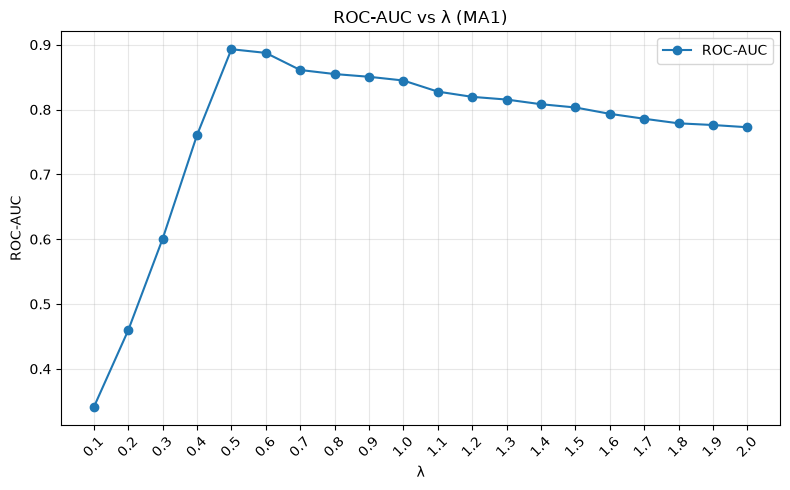

In [7]:
### Cell 7
import matplotlib.pyplot as plt
lambda_list = [0.1, 0.2, 0.3, 0.4, 0.5,
               0.6, 0.7, 0.8, 0.9, 1.0,
               1.1, 1.2, 1.3, 1.4, 1.5,
               1.6, 1.7, 1.8, 1.9, 2.0]
roc_auc_ma1 = [r['ROC-AUC'] for r in all_results['MA1']]

plt.figure(figsize=(8, 5))
plt.plot(lambda_list, roc_auc_ma1, marker='o', linestyle='-',
         color='C0', label='ROC-AUC')
plt.title('ROC-AUC vs λ (MA1)')
plt.xlabel('λ')
plt.ylabel('ROC-AUC')
plt.xticks(lambda_list, rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### 🔴 Section 2: New Approach on MA's

#### ⚪ 1. New Main Code

In [8]:
# Cell 9
import numpy as np
import time
from sklearn.metrics import roc_auc_score, average_precision_score

# بازنویسی تابع برای پذیرش آرایه‌ای از لامبداها به ازای هر فیچر
def WNCROD_optimized_multi_lambda(data, X_tem, lambdas, block_size=None, sorted_kernel=True):
    data = np.asarray(data)
    n, m = data.shape

    X_tem = np.asarray(X_tem)
    if X_tem.dtype == np.bool_:
        X_idx = np.flatnonzero(X_tem)
    else:
        X_idx = np.ascontiguousarray(X_tem, dtype=np.intp).ravel()
    n_X = X_idx.size
    if n_X == 0:
        return np.zeros(0, dtype=np.float64)

    in_X = np.zeros(n, dtype=bool)
    in_X[X_idx] = True
    C_idx = np.flatnonzero(~in_X)

    D1, D2, D3 = m / 3, m / 2, 0.9 * m
    delta = np.zeros(m)
    ID = np.all(data <= 1, axis=0)
    
    # اعمال لامبداهای مجزا برای هر فیچر
    lambdas_arr = np.asarray(lambdas)
    if ID.any():
        delta[ID] = np.std(data[:, ID], axis=0) / lambdas_arr[ID]

    om = np.arange(m + 1)
    s1, s2, s3 = om <= D1, om >= D2, om >= D3
    k1 = m - int(om[s1].max()) if s1.any() else None
    k2 = m - int(om[s2].min()) if s2.any() else None
    k3 = m - int(om[s3].min()) if s3.any() else None

    work = np.ascontiguousarray(data, dtype=np.float64)
    VX = np.ascontiguousarray(work[X_idx].T)
    VC = np.ascontiguousarray(work[C_idx].T)
    del work

    if block_size is None:
        block_size = min(n_X, max(64, (1 << 21) // n_X))
    block_size = int(min(max(1, int(block_size)), n_X))

    POS = np.empty((m, n_X), dtype=bool)
    hit = np.empty((n_X, m), dtype=np.float64)
    if sorted_kernel:
        rank_all = np.empty((m, n_X), dtype=np.int32)
        lo_all = np.empty((m, n_X), dtype=np.int32)
        hi_all = np.empty((m, n_X), dtype=np.int32)
        iota = np.arange(n_X, dtype=np.intp)

    for j in range(m):
        v, eps = VX[j], delta[j]
        if sorted_kernel:
            order = np.argsort(v, kind="stable")
            s = v[order]
            rank = np.empty(n_X, dtype=np.intp)
            rank[order] = iota
            lo, hi = _neighbour_interval(v, s, rank, eps)
            rank_all[j] = rank
            lo_all[j] = lo
            hi_all[j] = hi
            hit[:, j] = hi - lo
            POS[j] = ~_has_outside_neighbour_sorted(v, VC[j], eps)
        else:
            POS[j] = ~_has_outside_neighbour_dense(v, VC[j], eps, block_size)

    NIB = ~POS
    NEB = NIB.all(axis=0)
    NPB = NIB & ~NEB
    del NIB

    gemm_dt = np.float32 if n_X < (1 << 24) else np.float64
    NPB_f = np.ascontiguousarray(NPB.T, dtype=gemm_dt)
    POS_f = np.ascontiguousarray(POS.T, dtype=gemm_dt)

    cnt_dt = np.uint8 if m <= 255 else (np.uint16 if m <= 65535 else np.uint32)
    cnt = np.empty((block_size, n_X), dtype=cnt_dt)
    buf1 = np.empty((block_size, n_X), dtype=bool)
    buf2 = np.empty((block_size, n_X), dtype=bool)
    fbuf = np.empty((block_size, n_X), dtype=gemm_dt)
    dbuf = None if sorted_kernel else np.empty((block_size, n_X), np.float64)

    neb_cnt = np.zeros(n_X, dtype=np.float64)
    npb_cnt = np.zeros((n_X, m), dtype=np.float64)
    pos_cnt = np.zeros((n_X, m), dtype=np.float64)

    for start in range(0, n_X, block_size):
        stop = min(start + block_size, n_X)
        b = stop - start
        c, a, t = cnt[:b], buf1[:b], buf2[:b]
        c.fill(0)

        for j in range(m):
            if sorted_kernel:
                r = rank_all[j]
                np.greater_equal(r, lo_all[j][start:stop, None], out=a)
                np.less(r, hi_all[j][start:stop, None], out=t)
                np.logical_and(a, t, out=a)
            else:
                v, d = VX[j], dbuf[:b]
                np.subtract(v[start:stop, None], v[None, :], out=d)
                np.abs(d, out=d)
                np.less_equal(d, delta[j], out=a)
                hit[start:stop, j] = np.count_nonzero(a, axis=1)
            c += a

        if k1 is not None:
            np.greater_equal(c, k1, out=a)
            np.logical_and(a, NEB, out=a)
            neb_cnt[start:stop] = np.count_nonzero(a, axis=1)
        if k2 is not None:
            np.less_equal(c, k2, out=a)
            np.copyto(fbuf[:b], a)
            npb_cnt[start:stop] = fbuf[:b] @ NPB_f
        if k3 is not None:
            np.less_equal(c, k3, out=a)
            np.copyto(fbuf[:b], a)
            pos_cnt[start:stop] = fbuf[:b] @ POS_f

    weight = 1 - np.sqrt(hit / n_X)
    ndf = neb_cnt[:, None] + pos_cnt + npb_cnt
    return np.mean((ndf / n_X) * weight, axis=1)

#### ⚪ 2. Manual execution on specific Lambda's

In [9]:
# Cell 10
# ارزیابی دستی لامبداها برای هر 3 دیتاست
def evaluate_wncrod_multi(data, labels, X_tem, lambdas):
    out_scores = WNCROD_optimized_multi_lambda(data, X_tem, lambdas)
    return roc_auc_score(labels[X_tem], out_scores), average_precision_score(labels[X_tem], out_scores)

# می‌توانید مقادیر این لیست را دستی تغییر دهید
manual_lambdas = [0.5, 0.5, 0.5, 0.5, 0.5, 0.5] 
print(f"--- Testing Manual Lambdas: {manual_lambdas} ---")

for name, X_tem in [('MA1', X_tem_ma1), ('MA2', X_tem_ma2), ('MA3', X_tem_ma3)]:
    t0 = time.perf_counter()
    roc_auc, ap = evaluate_wncrod_multi(X, y, X_tem, manual_lambdas)
    elapsed = time.perf_counter() - t0
    print(f"{name}: ROC-AUC = {roc_auc:.4f}, AP = {ap:.4f} [Time: {elapsed:.2f} s]")

--- Testing Manual Lambdas: [0.5, 0.5, 0.5, 0.5, 0.5, 0.5] ---
MA1: ROC-AUC = 0.8931, AP = 0.3550 [Time: 1.50 s]
MA2: ROC-AUC = 0.7745, AP = 0.0626 [Time: 1.45 s]
MA3: ROC-AUC = 0.7748, AP = 0.0827 [Time: 0.87 s]


#### ⚪ 3. Greedy Serch for all MA's

In [10]:
# Cell 11
def sequential_lambda_search(data, labels, X_tem, dataset_name):
    num_features = data.shape[1]
    lambda_space = [round(x, 1) for x in np.arange(0.1, 2.1, 0.1)]

    best_lambdas_ap = [1.0] * num_features
    best_lambdas_roc = [1.0] * num_features

    history_ap = {f: [] for f in range(num_features)}
    history_roc = {f: [] for f in range(num_features)}

    print(f"\n========== Starting Method 1 Search on {dataset_name} ==========")
    total_t0 = time.perf_counter()

    for f in range(num_features):
        f_t0 = time.perf_counter()
        print(f"--- Optimizing Feature {f+1} ---")

        best_ap_val = -1.0
        best_roc_val = -1.0
        best_lam_for_ap = 1.0
        best_lam_for_roc = 1.0

        for lam in lambda_space:
            # مسیر اول: ارزیابی مستقل برای AP
            current_test_ap = list(best_lambdas_ap)
            current_test_ap[f] = lam
            _, ap_score = evaluate_wncrod_multi(data, labels, X_tem, current_test_ap)
            history_ap[f].append(ap_score)

            if ap_score > best_ap_val:
                best_ap_val = ap_score
                best_lam_for_ap = lam

            # مسیر دوم: ارزیابی مستقل برای ROC-AUC
            current_test_roc = list(best_lambdas_roc)
            current_test_roc[f] = lam
            roc_score, _ = evaluate_wncrod_multi(data, labels, X_tem, current_test_roc)
            history_roc[f].append(roc_score)

            if roc_score > best_roc_val:
                best_roc_val = roc_score
                best_lam_for_roc = lam

        # قفل کردن بهترین مقدار برای فیچرهای بعدی
        best_lambdas_ap[f] = best_lam_for_ap
        best_lambdas_roc[f] = best_lam_for_roc

        f_elapsed = time.perf_counter() - f_t0
        print(f"Feature {f+1} Done in {f_elapsed:.2f}s | Locked AP lam: {best_lam_for_ap} (AP: {best_ap_val:.4f}) | Locked ROC lam: {best_lam_for_roc} (ROC: {best_roc_val:.4f})")

    print(f"\nTotal Search Time for {dataset_name}: {time.perf_counter() - total_t0:.2f}s")
    print(f"Final Best Lambdas for AP:      {best_lambdas_ap}")
    print(f"Final Best Lambdas for ROC-AUC: {best_lambdas_roc}")

    return best_lambdas_ap, best_lambdas_roc, history_ap, history_roc, lambda_space

# اجرای سرچ روی تمام دیتاست‌ها و ذخیره نتایج
all_datasets_results = {}

for name, X_tem in [('MA1', X_tem_ma1), ('MA2', X_tem_ma2), ('MA3', X_tem_ma3)]:
    ap_opt, roc_opt, hist_ap, hist_roc, l_space = sequential_lambda_search(X, y, X_tem, name)
    all_datasets_results[name] = {
        'ap_opt': ap_opt,
        'roc_opt': roc_opt,
        'hist_ap': hist_ap,
        'hist_roc': hist_roc,
        'l_space': l_space
    }


========== Starting Method 1 Search on MA1 ==========
--- Optimizing Feature 1 ---
Feature 1 Done in 66.46s | Locked AP lam: 0.3 (AP: 0.1108) | Locked ROC lam: 0.5 (ROC: 0.8508)
--- Optimizing Feature 2 ---
Feature 2 Done in 66.28s | Locked AP lam: 0.1 (AP: 0.2991) | Locked ROC lam: 0.1 (ROC: 0.8827)
--- Optimizing Feature 3 ---
Feature 3 Done in 56.55s | Locked AP lam: 0.1 (AP: 0.4365) | Locked ROC lam: 0.1 (ROC: 0.9046)
--- Optimizing Feature 4 ---
Feature 4 Done in 56.40s | Locked AP lam: 0.5 (AP: 0.5109) | Locked ROC lam: 0.6 (ROC: 0.9062)
--- Optimizing Feature 5 ---
Feature 5 Done in 59.20s | Locked AP lam: 0.7 (AP: 0.5301) | Locked ROC lam: 0.7 (ROC: 0.9096)
--- Optimizing Feature 6 ---
Feature 6 Done in 72.40s | Locked AP lam: 0.5 (AP: 0.5645) | Locked ROC lam: 0.5 (ROC: 0.9191)

Total Search Time for MA1: 377.30s
Final Best Lambdas for AP:      [np.float64(0.3), np.float64(0.1), np.float64(0.1), np.float64(0.5), np.float64(0.7), np.float64(0.5)]
Final Best Lambdas for ROC-AUC

#### ⚪ 4. Plot Sequential Lambda Optimization

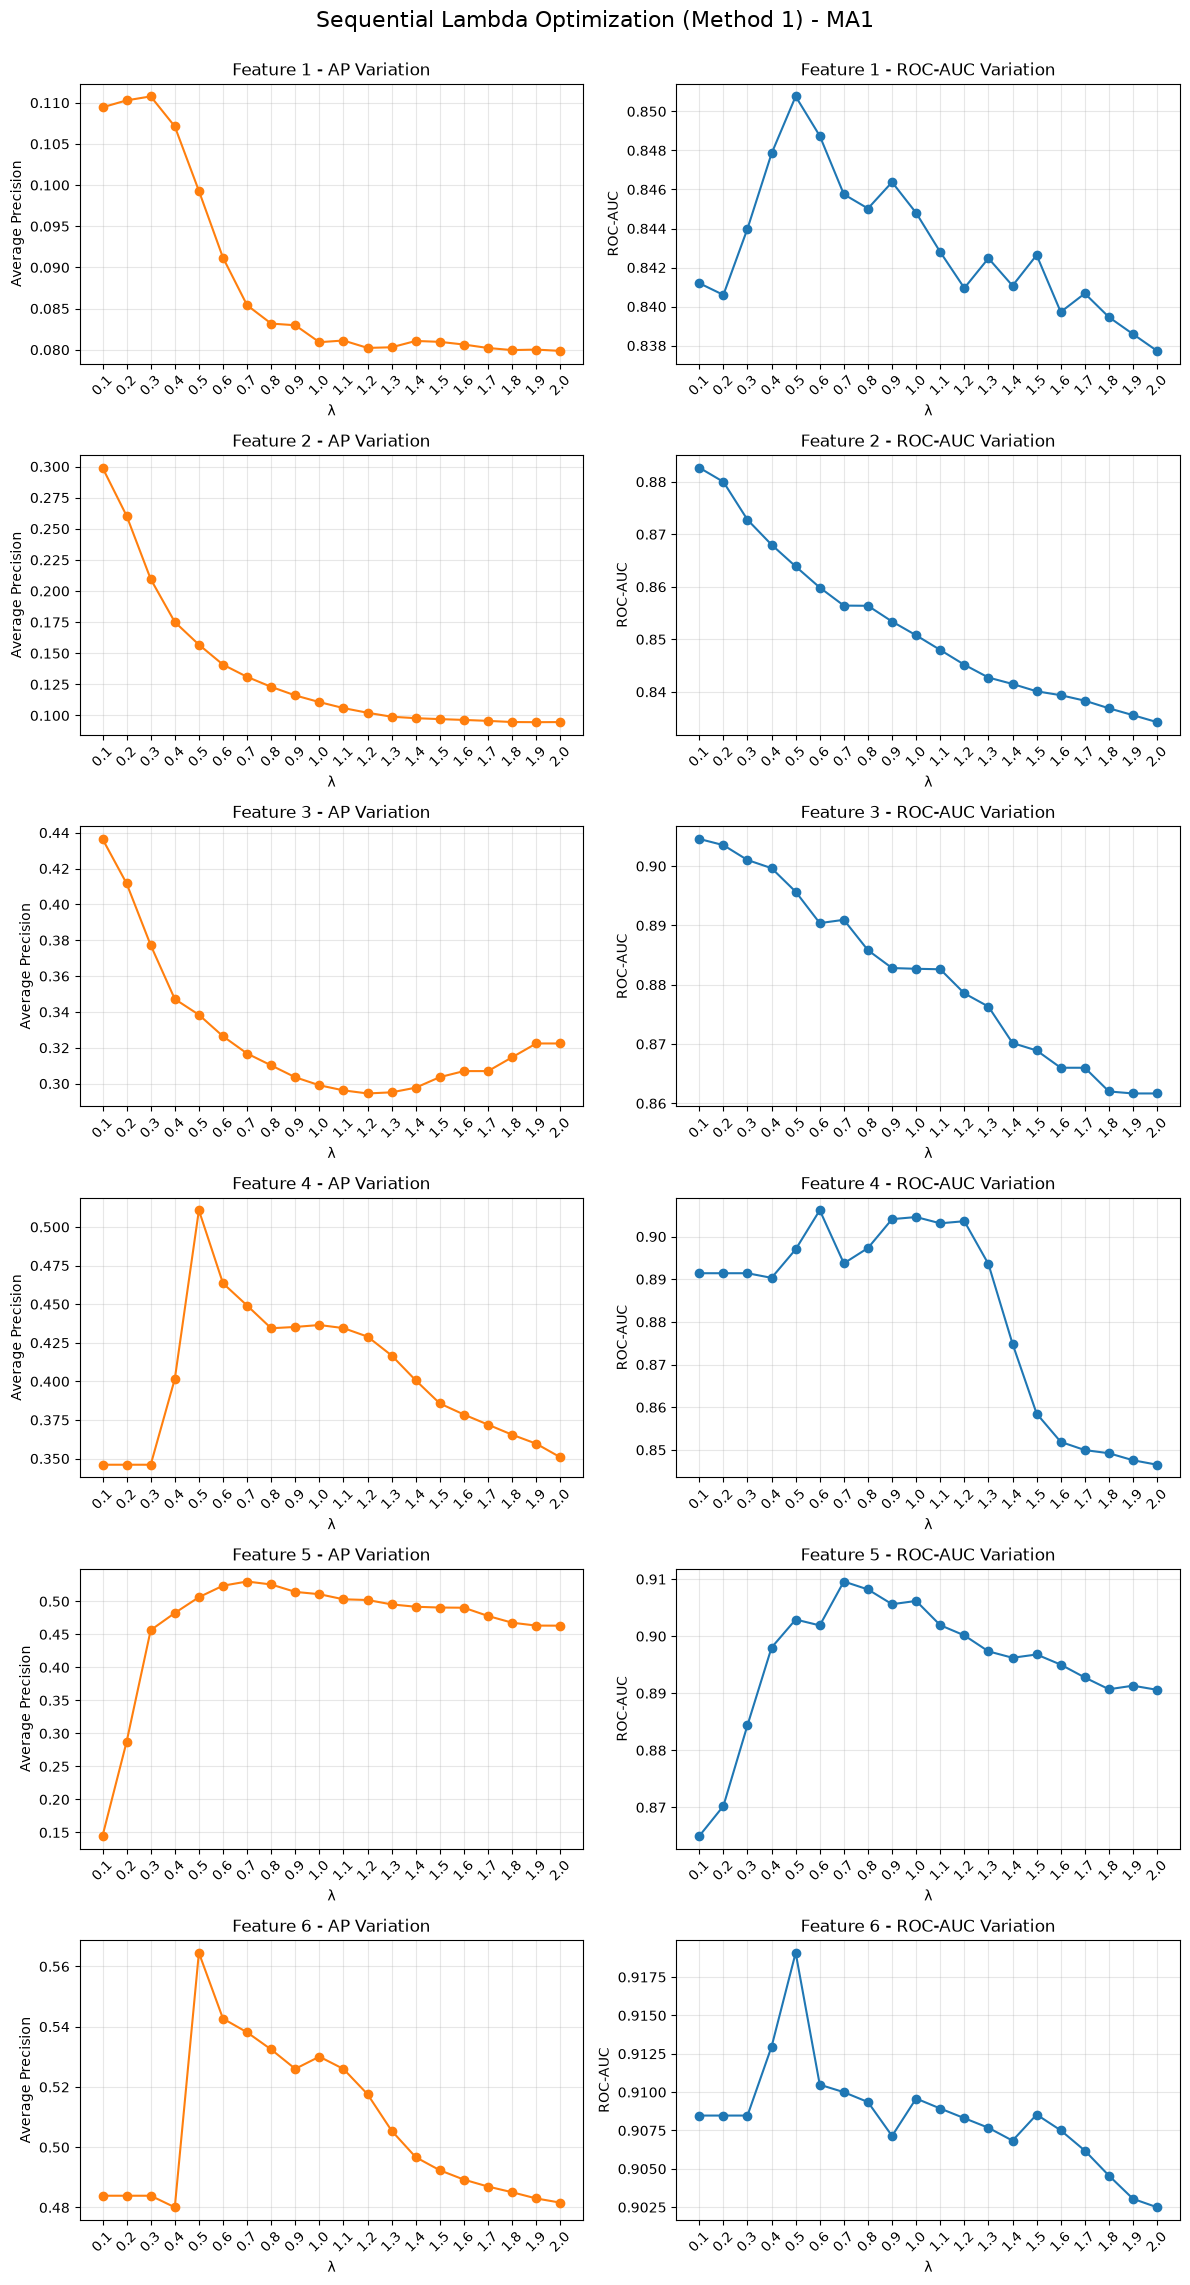

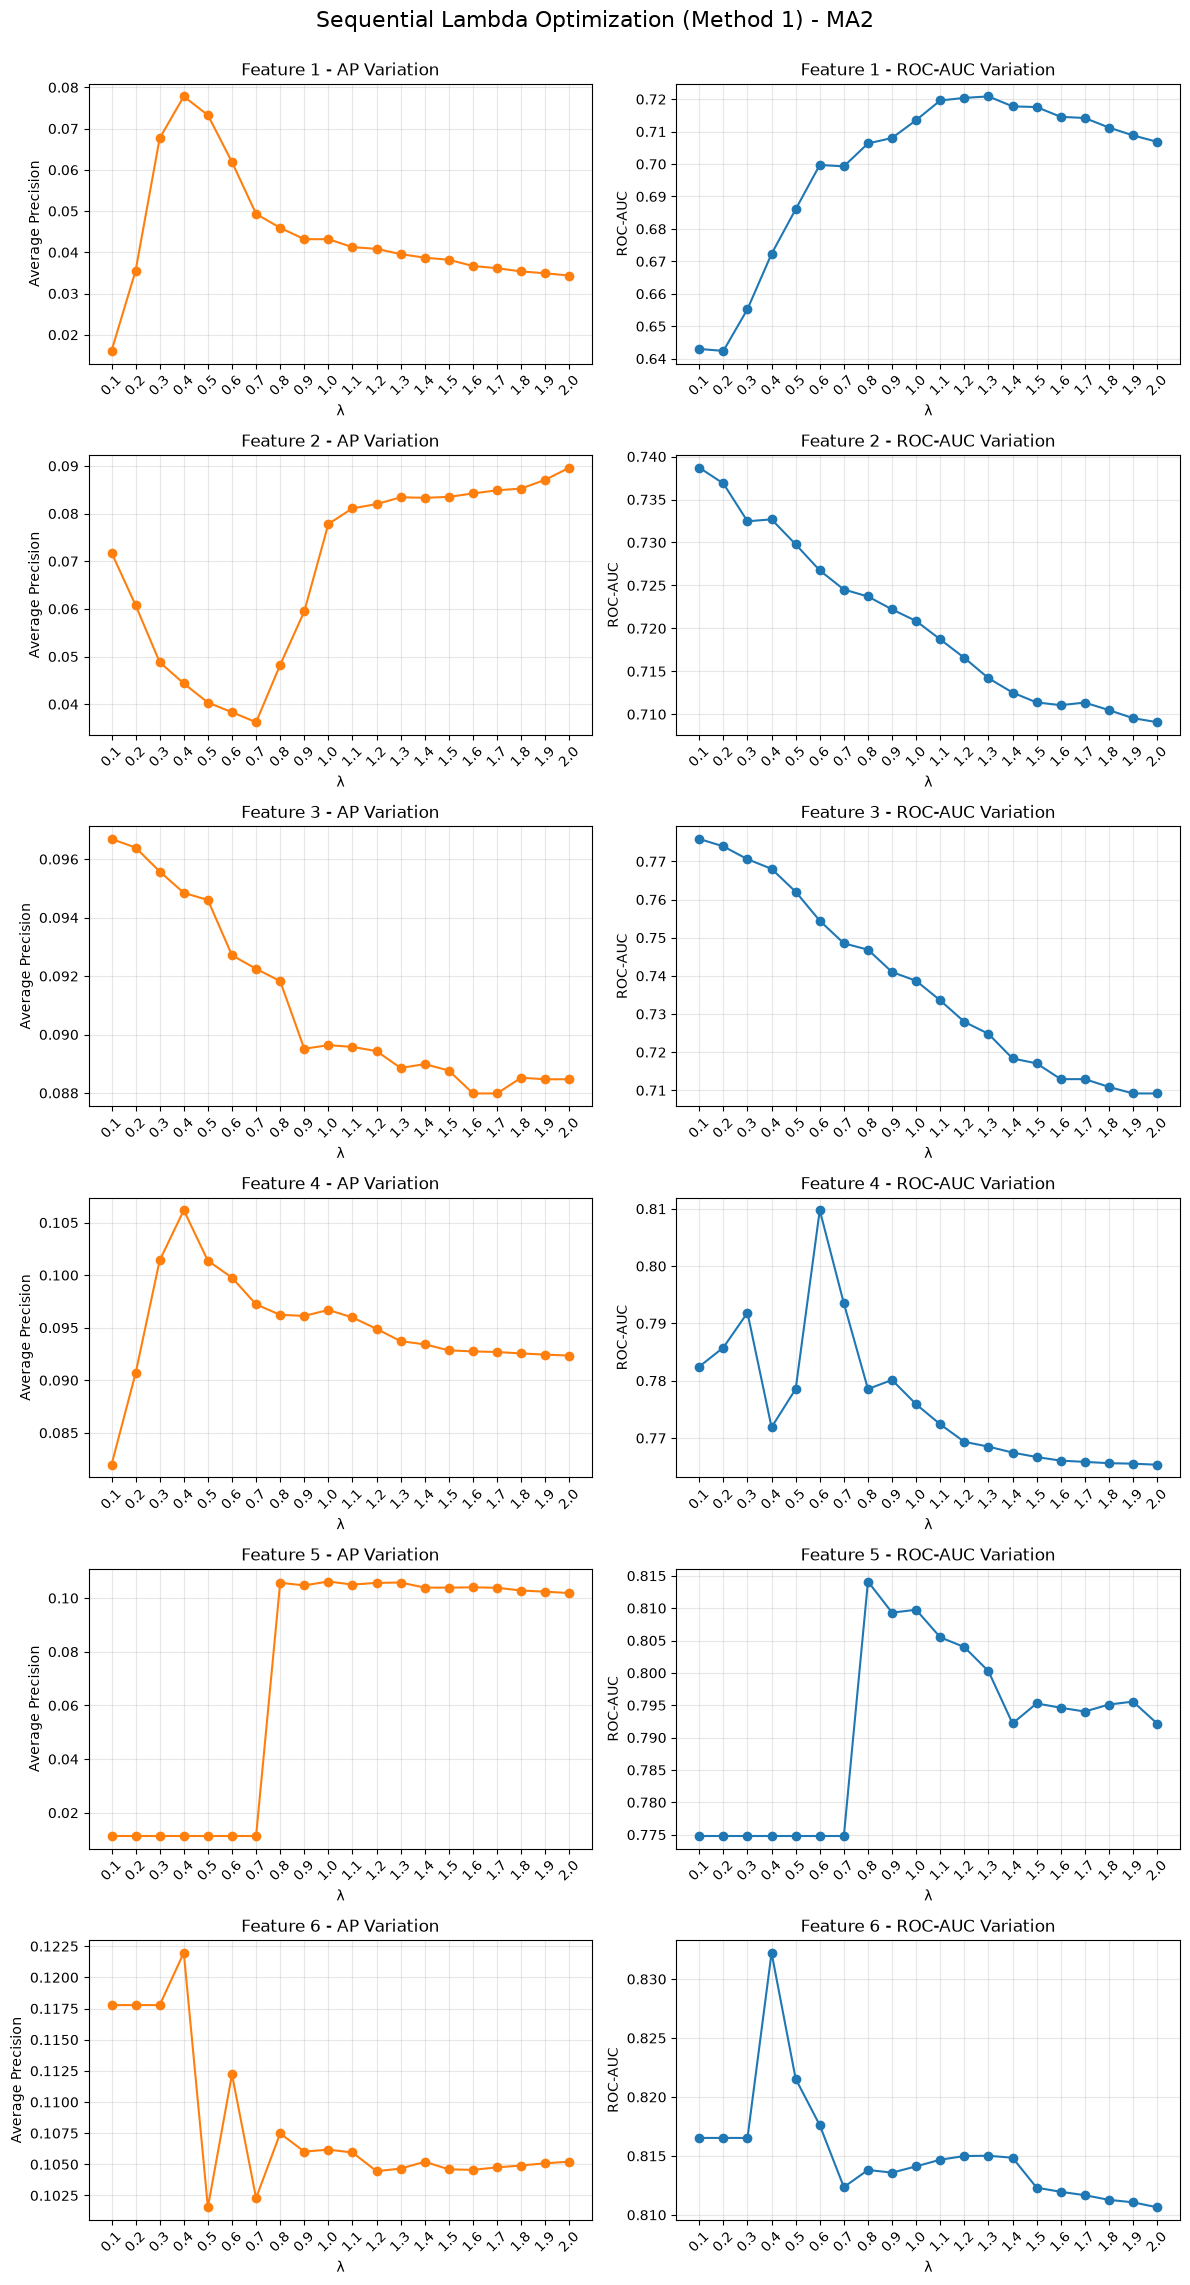

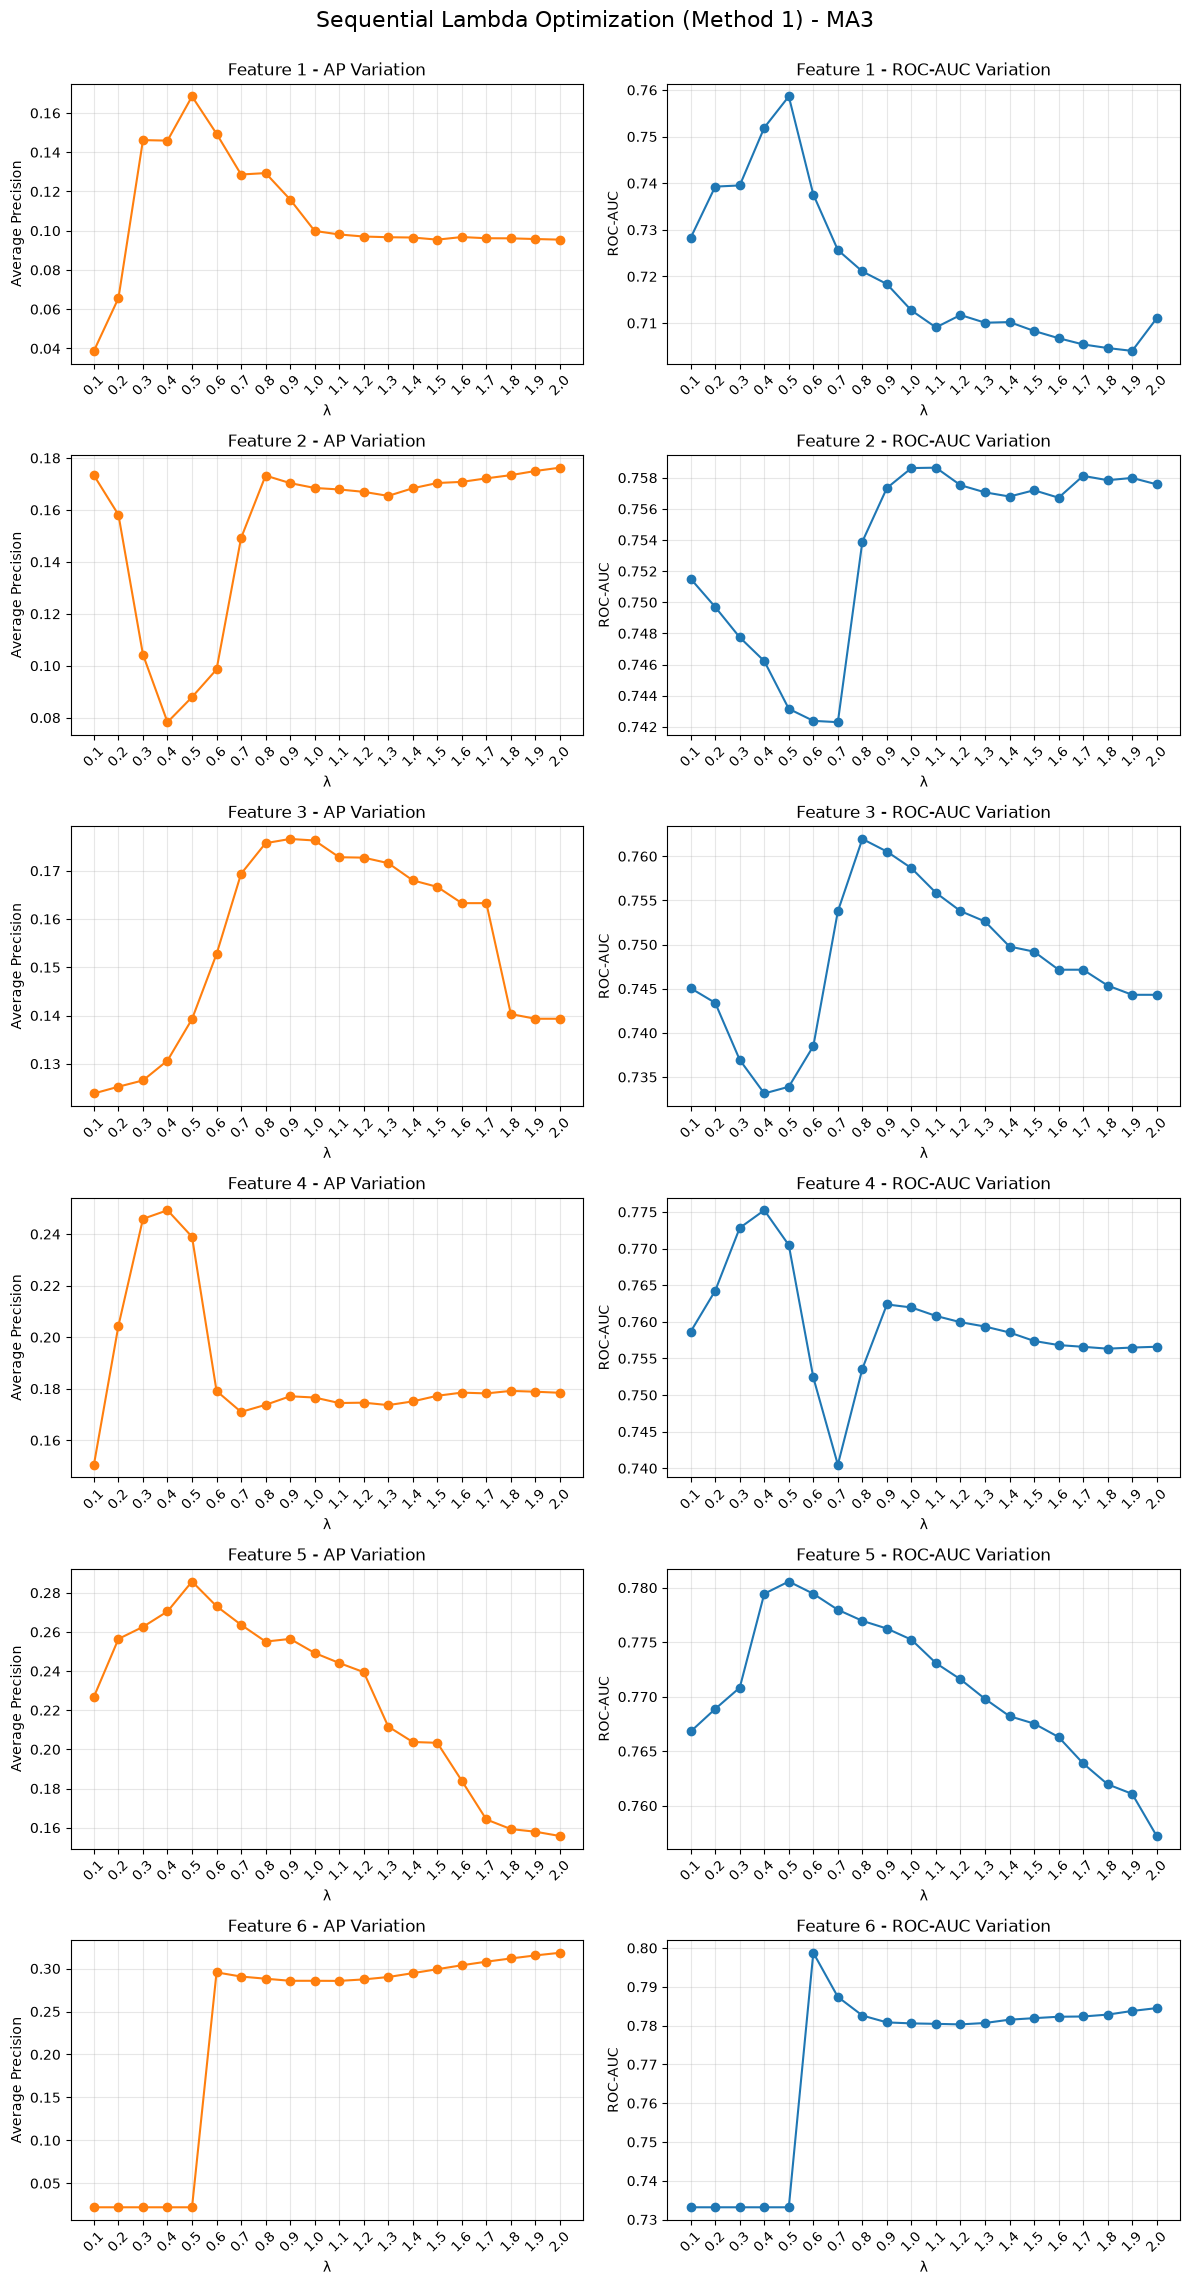

In [11]:
# Cell 12
import matplotlib.pyplot as plt

# تابع رسم نمودارها
def plot_search_history(history_ap, history_roc, lambda_space, dataset_name):
    num_features = len(history_ap)
    fig, axes = plt.subplots(num_features, 2, figsize=(12, 4 * num_features))
    fig.suptitle(f'Sequential Lambda Optimization (Method 1) - {dataset_name}', fontsize=16)

    for f in range(num_features):
        # نمودار AP
        axes[f, 0].plot(lambda_space, history_ap[f], marker='o', color='C1')
        axes[f, 0].set_title(f'Feature {f+1} - AP Variation')
        axes[f, 0].set_xlabel('λ')
        axes[f, 0].set_ylabel('Average Precision')
        axes[f, 0].set_xticks(lambda_space)
        axes[f, 0].tick_params(axis='x', rotation=45)
        axes[f, 0].grid(alpha=0.3)

        # نمودار ROC-AUC
        axes[f, 1].plot(lambda_space, history_roc[f], marker='o', color='C0')
        axes[f, 1].set_title(f'Feature {f+1} - ROC-AUC Variation')
        axes[f, 1].set_xlabel('λ')
        axes[f, 1].set_ylabel('ROC-AUC')
        axes[f, 1].set_xticks(lambda_space)
        axes[f, 1].tick_params(axis='x', rotation=45)
        axes[f, 1].grid(alpha=0.3)

    plt.tight_layout(rect=[0, 0.03, 1, 0.98])
    plt.show()

# رسم نمودارها به ازای هر دیتاست
for name in ['MA1', 'MA2', 'MA3']:
    res = all_datasets_results[name]
    plot_search_history(res['hist_ap'], res['hist_roc'], res['l_space'], name)

#### ⚪ 5. Optimization #1: Random Search

In [12]:
# Cell 13
import numpy as np
import time

def random_search_lambdas(data, labels, X_tem, dataset_name, num_iterations=500):
    num_features = data.shape[1]
    # فضای جستجوی گسسته مشابه حالت قبل
    lambda_space = np.round(np.arange(0.1, 2.1, 0.1), 1)

    best_ap_val = -1.0
    best_roc_val = -1.0
    best_lambdas_ap = None
    best_lambdas_roc = None

    # تاریخچه برای رسم نمودار همگرایی (روند بهبود بهترین جواب یافت شده)
    history_best_ap = []
    history_best_roc = []

    print(f"\n========== Starting Random Search on {dataset_name} ({num_iterations} iterations) ==========")
    total_t0 = time.perf_counter()

    for i in range(num_iterations):
        # انتخاب تصادفی یک ترکیب ۶ تایی از مقادیر لامبدا
        current_lambdas = np.random.choice(lambda_space, size=num_features)

        # ارزیابی این ترکیب تصادفی روی الگوریتم
        roc_score, ap_score = evaluate_wncrod_multi(data, labels, X_tem, current_lambdas)

        # بروزرسانی اگر بهترین AP تا این لحظه پیدا شد
        if ap_score > best_ap_val:
            best_ap_val = ap_score
            best_lambdas_ap = current_lambdas.copy()

        # بروزرسانی اگر بهترین ROC-AUC تا این لحظه پیدا شد
        if roc_score > best_roc_val:
            best_roc_val = roc_score
            best_lambdas_roc = current_lambdas.copy()

        # ثبت بهترین مقادیر تا این تکرار برای رسم نمودار همگرایی
        history_best_ap.append(best_ap_val)
        history_best_roc.append(best_roc_val)

        # چاپ وضعیت هر ۱۰۰ تکرار جهت مانیتورینگ
        if (i + 1) % 100 == 0:
            print(f"Iter {i+1}/{num_iterations} | Best AP: {best_ap_val:.4f} | Best ROC: {best_roc_val:.4f}")

    elapsed = time.perf_counter() - total_t0
    print(f"\nSearch Time for {dataset_name}: {elapsed:.2f}s")
    print(f"Final Best AP: {best_ap_val:.4f} -> Combination: {best_lambdas_ap}")
    print(f"Final Best ROC-AUC: {best_roc_val:.4f} -> Combination: {best_lambdas_roc}")

    return best_lambdas_ap, best_lambdas_roc, history_best_ap, history_best_roc

In [13]:
# Cell 14
# اجرای جستجوی تصادفی به صورت مستقل روی هر سه دیتاست
# می‌توانید تعداد تکرار را بسته به قدرت سیستم بالاتر ببرید (مثلا 1000)
num_iters = 500 
random_search_results = {}

for name, X_tem in [('MA1', X_tem_ma1), ('MA2', X_tem_ma2), ('MA3', X_tem_ma3)]:
    ap_opt, roc_opt, hist_ap, hist_roc = random_search_lambdas(X, y, X_tem, name, num_iterations=num_iters)
    
    random_search_results[name] = {
        'ap_opt': ap_opt,
        'roc_opt': roc_opt,
        'hist_ap': hist_ap,
        'hist_roc': hist_roc
    }


========== Starting Random Search on MA1 (500 iterations) ==========
Iter 100/500 | Best AP: 0.3133 | Best ROC: 0.8729
Iter 200/500 | Best AP: 0.3562 | Best ROC: 0.8821
Iter 300/500 | Best AP: 0.3562 | Best ROC: 0.8854
Iter 400/500 | Best AP: 0.4007 | Best ROC: 0.8854
Iter 500/500 | Best AP: 0.4007 | Best ROC: 0.8854

Search Time for MA1: 920.30s
Final Best AP: 0.4007 -> Combination: [1.5 0.1 0.7 1.9 0.5 0.6]
Final Best ROC-AUC: 0.8854 -> Combination: [0.5 0.6 0.4 0.5 2.  0.5]

========== Starting Random Search on MA2 (500 iterations) ==========
Iter 100/500 | Best AP: 0.1041 | Best ROC: 0.7751
Iter 200/500 | Best AP: 0.1709 | Best ROC: 0.7804
Iter 300/500 | Best AP: 0.1709 | Best ROC: 0.7804
Iter 400/500 | Best AP: 0.1709 | Best ROC: 0.7804
Iter 500/500 | Best AP: 0.1709 | Best ROC: 0.7804

Search Time for MA2: 724.85s
Final Best AP: 0.1709 -> Combination: [1.9 0.6 0.7 1.9 0.1 0.1]
Final Best ROC-AUC: 0.7804 -> Combination: [1.9 0.6 0.7 1.9 0.1 0.1]

========== Starting Random Search

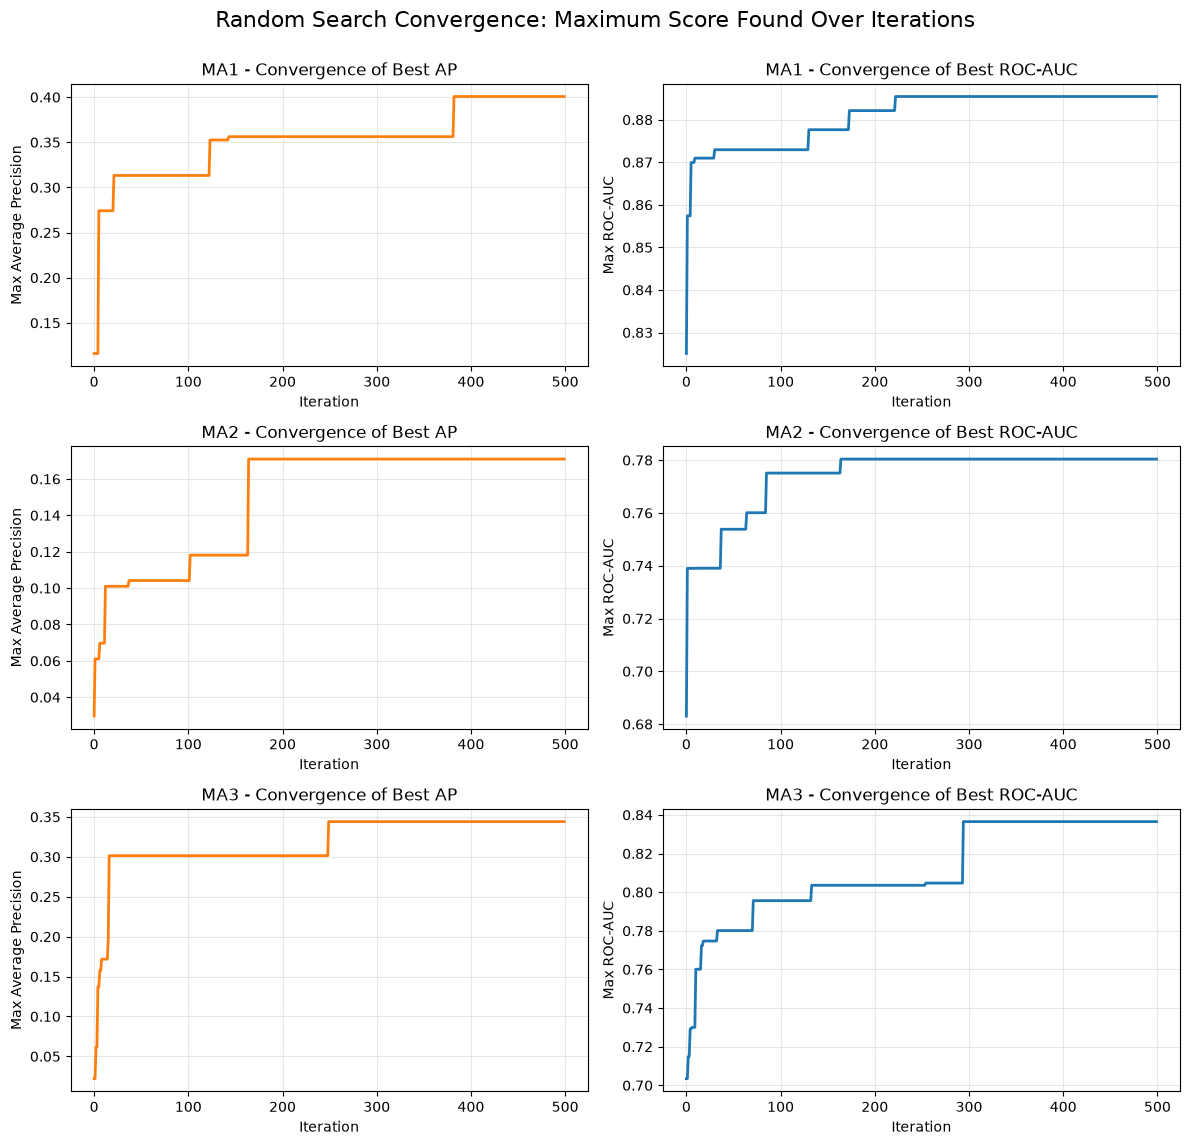

In [14]:
# Cell 15
import matplotlib.pyplot as plt

# رسم نمودار همگرایی به جای نمودار تغییرات یک فیچر
# این نمودار نشان می‌دهد که چگونه در طول تکرارها، پاسخ‌های بهتری پیدا شده‌اند
fig, axes = plt.subplots(3, 2, figsize=(12, 12))
fig.suptitle('Random Search Convergence: Maximum Score Found Over Iterations', fontsize=16)

subsets = ['MA1', 'MA2', 'MA3']
for idx, name in enumerate(subsets):
    res = random_search_results[name]

    # نمودار همگرایی AP
    axes[idx, 0].plot(res['hist_ap'], color='C1', linewidth=2)
    axes[idx, 0].set_title(f'{name} - Convergence of Best AP')
    axes[idx, 0].set_xlabel('Iteration')
    axes[idx, 0].set_ylabel('Max Average Precision')
    axes[idx, 0].grid(alpha=0.3)

    # نمودار همگرایی ROC-AUC
    axes[idx, 1].plot(res['hist_roc'], color='C0', linewidth=2)
    axes[idx, 1].set_title(f'{name} - Convergence of Best ROC-AUC')
    axes[idx, 1].set_xlabel('Iteration')
    axes[idx, 1].set_ylabel('Max ROC-AUC')
    axes[idx, 1].grid(alpha=0.3)

plt.tight_layout(rect=[0, 0.03, 1, 0.98])
plt.show()

#### ⚪ 6. Optimization #2: Baysian Optimization

### 🔴 Section 3: Merging FeatureWise & Gen1

#### ⚪ Base Codes

In [25]:
# Cell 16
try:
    opus_module = importlib.import_module("1_opus_5_thinking")
except ModuleNotFoundError:
    opus_module = importlib.import_module("opus_5_thinking")

def _neighbour_interval(x, s, rank, eps):
    k = x.size
    if not eps >= 0:
        z = np.zeros(k, dtype=np.intp)
        return z, z.copy()
    lo = np.zeros(k, dtype=np.intp)
    hi = rank.astype(np.intp, copy=True)
    while True:
        act = lo < hi
        if not act.any(): break
        mid = (lo + hi) >> 1
        ok = np.abs(x - s[mid]) <= eps
        np.copyto(hi, mid, where=act & ok)
        np.copyto(lo, mid + 1, where=act & ~ok)
    left = lo
    lo = rank.astype(np.intp, copy=True)
    hi = np.full(k, k - 1, dtype=np.intp)
    while True:
        act = lo < hi
        if not act.any(): break
        mid = (lo + hi + 1) >> 1
        ok = np.abs(x - s[mid]) <= eps
        np.copyto(lo, mid, where=act & ok)
        np.copyto(hi, mid - 1, where=act & ~ok)
    return left, lo + 1

def _has_outside_neighbour_sorted(x, out_vals, eps):
    res = np.zeros(x.size, dtype=bool)
    if out_vals.size == 0 or not eps >= 0: return res
    s = np.sort(out_vals)
    pos = np.searchsorted(s, x, side="left")
    up = np.minimum(pos, s.size - 1)
    dn = np.maximum(pos - 1, 0)
    np.logical_or((pos < s.size) & (np.abs(x - s[up]) <= eps),
                  (pos > 0) & (np.abs(x - s[dn]) <= eps), out=res)
    return res

def fast_evaluate_variant(data, labels, X_tem, lambdas, variant_name, numeric_mask):
    n, m = data.shape
    X_tem_arr = np.asarray(X_tem)
    X_idx = np.flatnonzero(X_tem_arr) if X_tem_arr.dtype == np.bool_ else np.ascontiguousarray(X_tem_arr, dtype=np.intp).ravel()
    n_X = X_idx.size
    in_X = np.zeros(n, dtype=bool)
    in_X[X_idx] = True
    C_idx = np.flatnonzero(~in_X)
    D1, D2, D3 = m / 3, m / 2, 0.9 * m
    delta = np.zeros(m)
    floor = 1.0 / n
    
    for j in np.flatnonzero(numeric_mask):
        col = data[:, j]
        lam_j = float(lambdas[j]) if j < len(lambdas) else 1.0
        if "V5" in variant_name:
            scale = opus_module.madn(col)
            delta[j] = scale / lam_j if scale > 0 else 0.0
        elif "V6" in variant_name:
            scale = opus_module._min_positive(opus_module.madn(col), opus_module.iqr(col)/1.34)
            delta[j] = scale / lam_j if scale > 0 else 0.0
        elif "V8" in variant_name:
            scale = opus_module._std(col)
            delta[j] = max(scale / lam_j, floor) if scale > 0 else 0.0
        else: 
            delta[j] = opus_module._std(col) / lam_j
            
    work = np.ascontiguousarray(data, dtype=np.float64)
    VX = np.ascontiguousarray(work[X_idx].T)
    VC = np.ascontiguousarray(work[C_idx].T)
    block_size = min(n_X, max(64, (1 << 21) // n_X))
    POS = np.empty((m, n_X), dtype=bool)
    hit = np.empty((n_X, m), dtype=np.float64)
    neg_size = np.zeros(m, dtype=np.float64)
    iota = np.arange(n_X, dtype=np.intp)
    rank_all = np.empty((m, n_X), dtype=np.int32)
    lo_all = np.empty((m, n_X), dtype=np.int32)
    hi_all = np.empty((m, n_X), dtype=np.int32)
    
    for j in range(m):
        v, eps = VX[j], delta[j]
        order = np.argsort(v, kind="stable")
        s = v[order]
        rank = np.empty(n_X, dtype=np.intp)
        rank[order] = iota
        lo, hi = _neighbour_interval(v, s, rank, eps)
        rank_all[j] = rank
        lo_all[j] = lo
        hi_all[j] = hi
        hit[:, j] = hi - lo
        POS[j] = ~_has_outside_neighbour_sorted(v, VC[j], eps)
        if "V2" in variant_name:
            vc_j = VC[j]
            neg_size[j] = (~_has_outside_neighbour_sorted(vc_j, v, eps)).sum() if vc_j.size > 0 else 0.0
                
    NIB = ~POS
    NEB = NIB.all(axis=0)
    NPB = NIB & ~NEB
    NPB_f = np.ascontiguousarray(NPB.T, dtype=np.float64)
    POS_f = np.ascontiguousarray(POS.T, dtype=np.float64)
    cnt = np.empty((block_size, n_X), dtype=np.uint32)
    buf1 = np.empty((block_size, n_X), dtype=bool)
    buf2 = np.empty((block_size, n_X), dtype=bool)
    fbuf = np.empty((block_size, n_X), dtype=np.float64)
    neb_cnt = np.zeros(n_X, dtype=np.float64)
    npb_cnt = np.zeros((n_X, m), dtype=np.float64)
    pos_cnt = np.zeros((n_X, m), dtype=np.float64)
    om = np.arange(m + 1)
    s1, s2, s3 = om <= D1, om >= D2, om >= D3
    k1 = m - int(om[s1].max()) if s1.any() else None
    k2 = m - int(om[s2].min()) if s2.any() else None
    k3 = m - int(om[s3].min()) if s3.any() else None
    
    for start in range(0, n_X, block_size):
        stop = min(start + block_size, n_X)
        b = stop - start
        c, a, t = cnt[:b], buf1[:b], buf2[:b]
        c.fill(0)
        for j in range(m):
            r = rank_all[j]
            np.greater_equal(r, lo_all[j][start:stop, None], out=a)
            np.less(r, hi_all[j][start:stop, None], out=t)
            np.logical_and(a, t, out=a)
            c += a
        if k1 is not None:
            np.greater_equal(c, k1, out=a)
            np.logical_and(a, NEB, out=a)
            neb_cnt[start:stop] = np.count_nonzero(a, axis=1)
        if k2 is not None:
            np.less_equal(c, k2, out=a)
            np.copyto(fbuf[:b], a)
            npb_cnt[start:stop] = fbuf[:b] @ NPB_f
        if k3 is not None:
            np.less_equal(c, k3, out=a)
            np.copyto(fbuf[:b], a)
            pos_cnt[start:stop] = fbuf[:b] @ POS_f
            
    omega = (1.0 - np.sqrt(hit / n_X)) / m
    if "V2" in variant_name:
        gamma = (POS.sum(axis=1) + neg_size) / n
        max_gamma = gamma.max()
        gamma_hat = gamma / max_gamma if max_gamma > 1e-12 else np.ones_like(gamma)
        omega = np.sqrt(omega) * np.sqrt(gamma_hat[None, :])
        
    if "V4" in variant_name:
        neb_size = NEB.sum()
        npb_size = NPB.sum(axis=1)
        pos_size = POS.sum(axis=1)
        w_neb = 1.0 - neb_size / n_X
        w_npb = 1.0 - npb_size / n_X
        w_pos = 1.0 - pos_size / n_X
        numer = w_neb * neb_cnt[:, None] + w_npb[None, :] * npb_cnt + w_pos[None, :] * pos_cnt
        denom = w_neb * neb_size + w_npb * npb_size + w_pos * pos_size
        ndf = np.zeros_like(numer)
        ok = denom > 1e-12
        ndf[:, ok] = numer[:, ok] / denom[ok][None, :]
    else:
        ndf = (neb_cnt[:, None] + pos_cnt + npb_cnt) / n_X  
    mnof = np.sum(ndf * omega, axis=1)
    return roc_auc_score(labels[X_tem], mnof), average_precision_score(labels[X_tem], mnof)

def prepare_eval_data(data, variant_name):
    numeric_mask = np.all(data <= 1, axis=0)
    eval_data = data.copy()
    if "V3" in variant_name:
        subspace = opus_module.synthesize_subspace_attribute(eval_data, numeric_mask, power_iters=10, random_state=0)
        if subspace.used:
            eval_data = np.column_stack([eval_data, subspace.attribute])
            numeric_mask = np.append(numeric_mask, True)
    return eval_data, numeric_mask

def comparative_search(data, labels, X_tem, subset_name, variant_name):
    eval_data, numeric_mask = prepare_eval_data(data, variant_name)
    num_features = eval_data.shape[1]
    lambda_space = np.round(np.arange(0.1, 2.1, 0.1), 1)
    num_evals = num_features * len(lambda_space) 
    print(f"\n{'-'*80}")
    print(f"Comparing 1-Pass Sequential vs Random Search: {variant_name} on {subset_name}")
    print(f"Total Computation Budget: {num_evals} evaluations per method")
    print(f"{'-'*80}")
    
    # 1. Single Pass Sequential Search
    seq_hist_ap, seq_hist_roc = [], []
    best_ap_seq, best_roc_seq = -1.0, -1.0
    lambdas_ap_seq = np.ones(num_features, dtype=float)
    lambdas_roc_seq = np.ones(num_features, dtype=float)
    
    t0_seq = time.perf_counter()
    for f in range(num_features):
        if "V3" in variant_name and f == num_features - 1:
            for _ in lambda_space:
                seq_hist_ap.append(best_ap_seq)
                seq_hist_roc.append(best_roc_seq)
            continue   
        best_lam_ap = lambdas_ap_seq[f]
        best_lam_roc = lambdas_roc_seq[f]
        
        for lam in lambda_space:
            test_ap = lambdas_ap_seq.copy(); test_ap[f] = lam
            test_roc = lambdas_roc_seq.copy(); test_roc[f] = lam
            roc, ap = fast_evaluate_variant(eval_data, labels, X_tem, test_ap, variant_name, numeric_mask)
            if ap > best_ap_seq: best_ap_seq = ap; best_lam_ap = lam
            seq_hist_ap.append(best_ap_seq)
            roc, ap = fast_evaluate_variant(eval_data, labels, X_tem, test_roc, variant_name, numeric_mask)
            if roc > best_roc_seq: best_roc_seq = roc; best_lam_roc = lam
            seq_hist_roc.append(best_roc_seq)
            
        lambdas_ap_seq[f] = best_lam_ap
        lambdas_roc_seq[f] = best_lam_roc
    time_seq = time.perf_counter() - t0_seq

    # 2. Random Search
    rnd_hist_ap, rnd_hist_roc = [], []
    best_ap_rnd, best_roc_rnd = -1.0, -1.0
    
    t0_rnd = time.perf_counter()
    for _ in range(num_evals):
        curr_lams = np.random.choice(lambda_space, size=num_features)
        if "V3" in variant_name: curr_lams[-1] = 1.0
        roc, ap = fast_evaluate_variant(eval_data, labels, X_tem, curr_lams, variant_name, numeric_mask)
        if ap > best_ap_rnd: best_ap_rnd = ap
        if roc > best_roc_rnd: best_roc_rnd = roc
        rnd_hist_ap.append(best_ap_rnd)
        rnd_hist_roc.append(best_roc_rnd)
    time_rnd = time.perf_counter() - t0_rnd
    print(f"Sequential | Time: {time_seq:.2f}s | Max AP: {best_ap_seq:.4f} | Max ROC: {best_roc_seq:.4f}")
    print(f"Random     | Time: {time_rnd:.2f}s | Max AP: {best_ap_rnd:.4f} | Max ROC: {best_roc_rnd:.4f}")
    
    return seq_hist_ap, seq_hist_roc, rnd_hist_ap, rnd_hist_roc

In [26]:
# Cell 17
def plot_comparison(hist_seq_ap, hist_seq_roc, hist_rnd_ap, hist_rnd_roc, variant_name, dataset_name):
    evals = list(range(1, len(hist_seq_ap) + 1))
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f'{variant_name} on {dataset_name}: 1-Pass Sequential vs Random Search', fontsize=14, fontweight='bold')
    axes[0].plot(evals, hist_seq_ap, color='C0', linewidth=2, label='1-Pass Sequential')
    axes[0].plot(evals, hist_rnd_ap, color='C1', linewidth=2, label='Random Search')
    axes[0].set_title('Best AP Found over Evaluations')
    axes[0].set_xlabel('Number of Model Evaluations')
    axes[0].set_ylabel('Average Precision')
    axes[0].grid(alpha=0.3)
    axes[0].legend()
    axes[1].plot(evals, hist_seq_roc, color='C0', linewidth=2, label='1-Pass Sequential')
    axes[1].plot(evals, hist_rnd_roc, color='C1', linewidth=2, label='Random Search')
    axes[1].set_title('Best ROC-AUC Found over Evaluations')
    axes[1].set_xlabel('Number of Model Evaluations')
    axes[1].set_ylabel('ROC-AUC')
    axes[1].grid(alpha=0.3)
    axes[1].legend()

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

#### ⚪ V0


--------------------------------------------------------------------------------
Comparing 1-Pass Sequential vs Random Search: V0 (Baseline) on MA1
Total Computation Budget: 120 evaluations per method
--------------------------------------------------------------------------------
Sequential | Time: 664.12s | Max AP: 0.5645 | Max ROC: 0.9191
Random     | Time: 316.59s | Max AP: 0.2452 | Max ROC: 0.8927


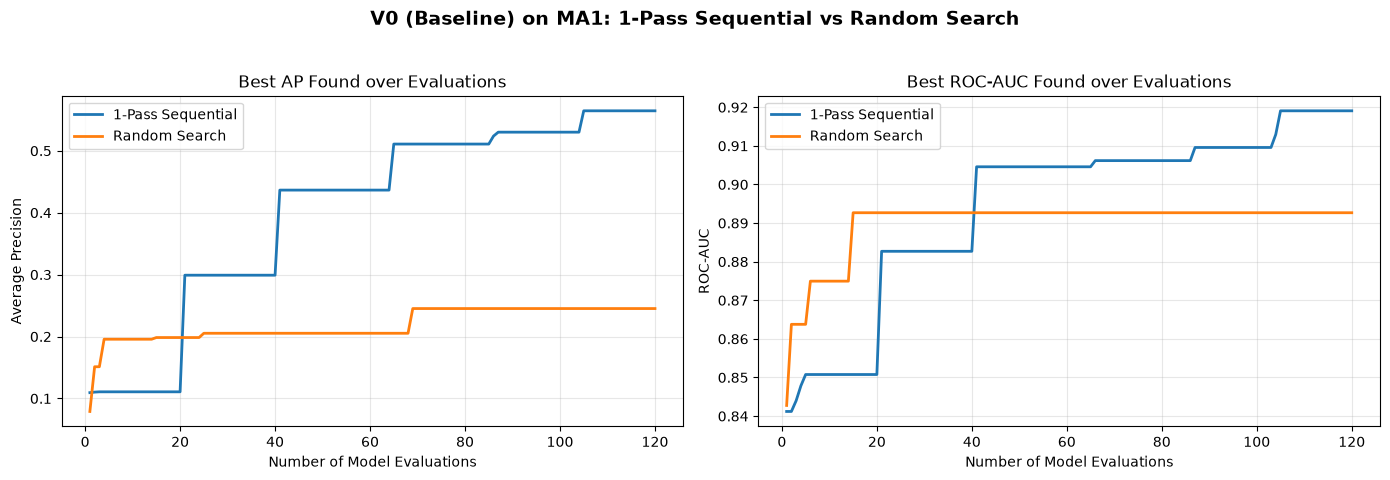


--------------------------------------------------------------------------------
Comparing 1-Pass Sequential vs Random Search: V0 (Baseline) on MA2
Total Computation Budget: 120 evaluations per method
--------------------------------------------------------------------------------
Sequential | Time: 546.59s | Max AP: 0.1220 | Max ROC: 0.8322
Random     | Time: 267.61s | Max AP: 0.1485 | Max ROC: 0.7813


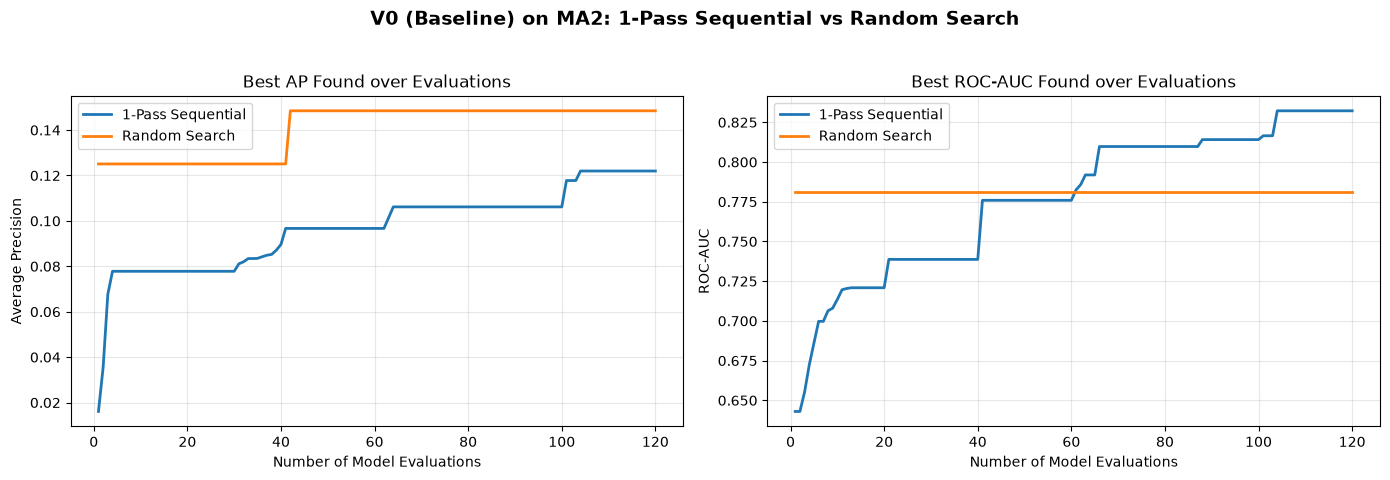


--------------------------------------------------------------------------------
Comparing 1-Pass Sequential vs Random Search: V0 (Baseline) on MA3
Total Computation Budget: 120 evaluations per method
--------------------------------------------------------------------------------
Sequential | Time: 341.00s | Max AP: 0.3184 | Max ROC: 0.7988
Random     | Time: 158.39s | Max AP: 0.3307 | Max ROC: 0.8036


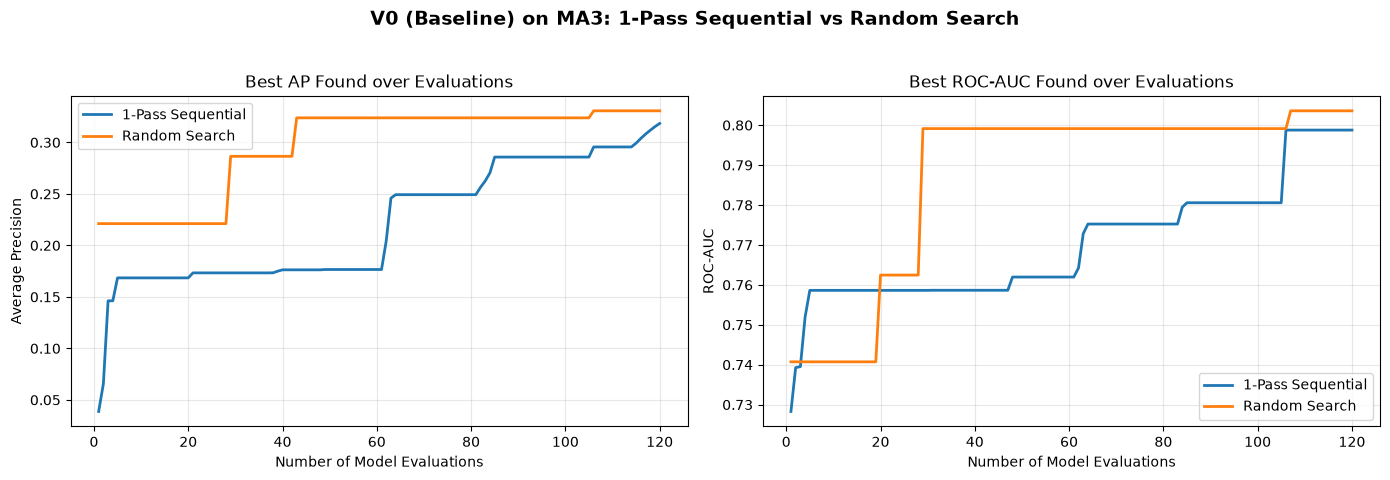

In [27]:
# Cell 18
# Execution for V0 (Baseline)
var_name = "V0 (Baseline)"
for name, X_tem in [('MA1', X_tem_ma1), ('MA2', X_tem_ma2), ('MA3', X_tem_ma3)]:
    s_ap, s_roc, r_ap, r_roc = comparative_search(X, y, X_tem, name, var_name)
    plot_comparison(s_ap, s_roc, r_ap, r_roc, var_name, name)

#### ⚪ V2


--------------------------------------------------------------------------------
Comparing 1-Pass Sequential vs Random Search: V2 (Discriminative Weights) on MA1
Total Computation Budget: 120 evaluations per method
--------------------------------------------------------------------------------
Sequential | Time: 548.46s | Max AP: 0.5211 | Max ROC: 0.8978
Random     | Time: 275.36s | Max AP: 0.4184 | Max ROC: 0.8880


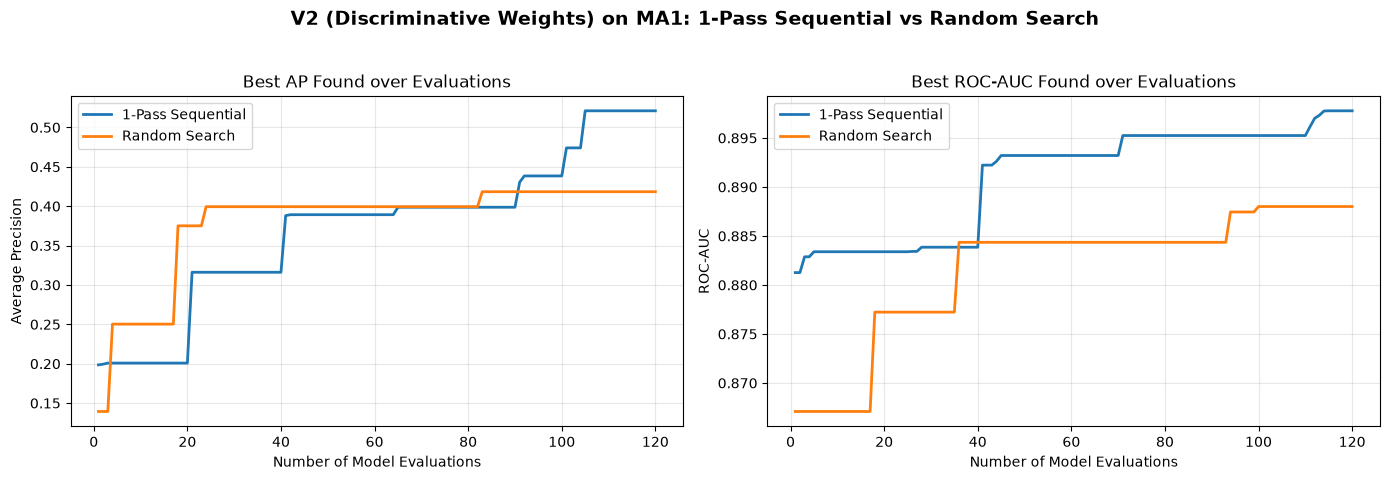


--------------------------------------------------------------------------------
Comparing 1-Pass Sequential vs Random Search: V2 (Discriminative Weights) on MA2
Total Computation Budget: 120 evaluations per method
--------------------------------------------------------------------------------
Sequential | Time: 471.48s | Max AP: 0.0755 | Max ROC: 0.7530
Random     | Time: 237.95s | Max AP: 0.0310 | Max ROC: 0.7397


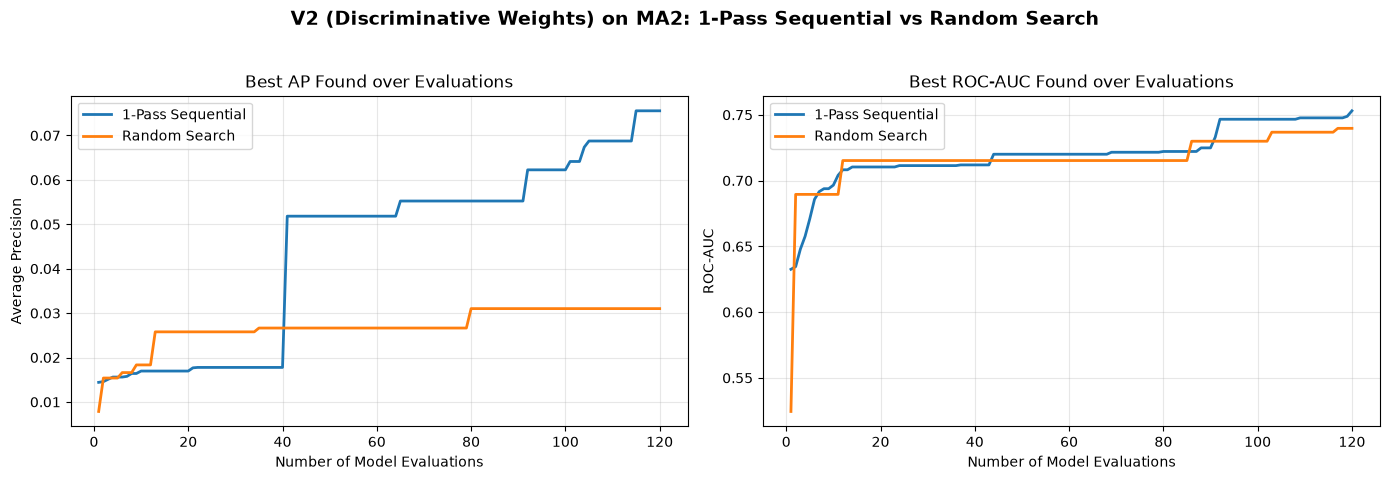


--------------------------------------------------------------------------------
Comparing 1-Pass Sequential vs Random Search: V2 (Discriminative Weights) on MA3
Total Computation Budget: 120 evaluations per method
--------------------------------------------------------------------------------
Sequential | Time: 317.31s | Max AP: 0.2932 | Max ROC: 0.7441
Random     | Time: 158.77s | Max AP: 0.1503 | Max ROC: 0.7404


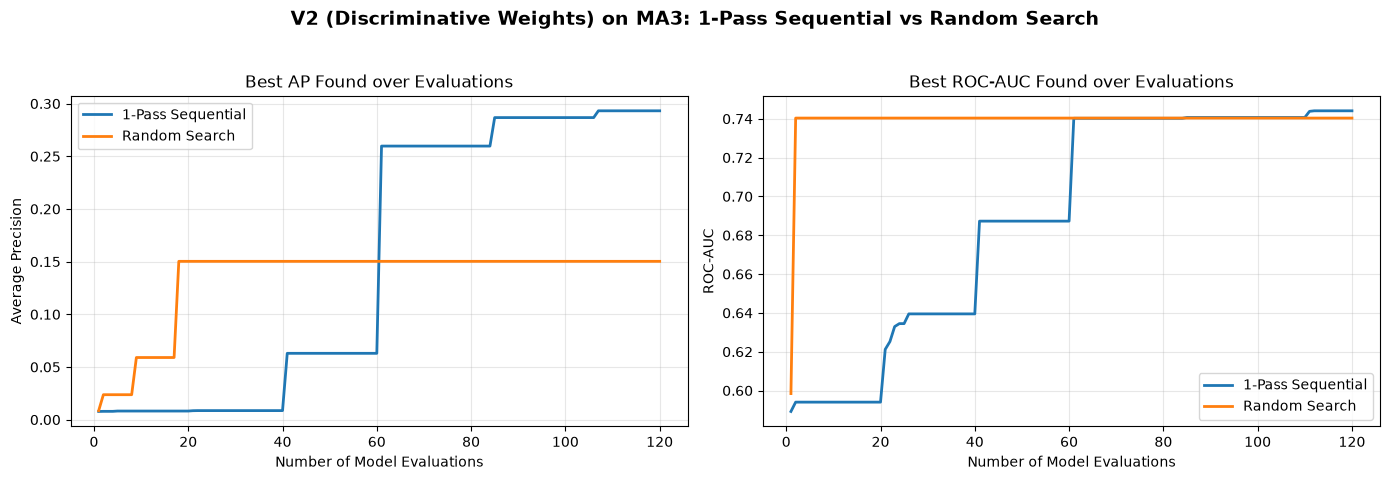

In [28]:
# Cell 19
# Execution for V2 (Discriminative Weights)
var_name = "V2 (Discriminative Weights)"
for name, X_tem in [('MA1', X_tem_ma1), ('MA2', X_tem_ma2), ('MA3', X_tem_ma3)]:
    s_ap, s_roc, r_ap, r_roc = comparative_search(X, y, X_tem, name, var_name)
    plot_comparison(s_ap, s_roc, r_ap, r_roc, var_name, name)

#### ⚪ V3


--------------------------------------------------------------------------------
Comparing 1-Pass Sequential vs Random Search: V3 (Subspace Augmented) on MA1
Total Computation Budget: 140 evaluations per method
--------------------------------------------------------------------------------
Sequential | Time: 582.51s | Max AP: 0.5532 | Max ROC: 0.8914
Random     | Time: 339.83s | Max AP: 0.3789 | Max ROC: 0.8758


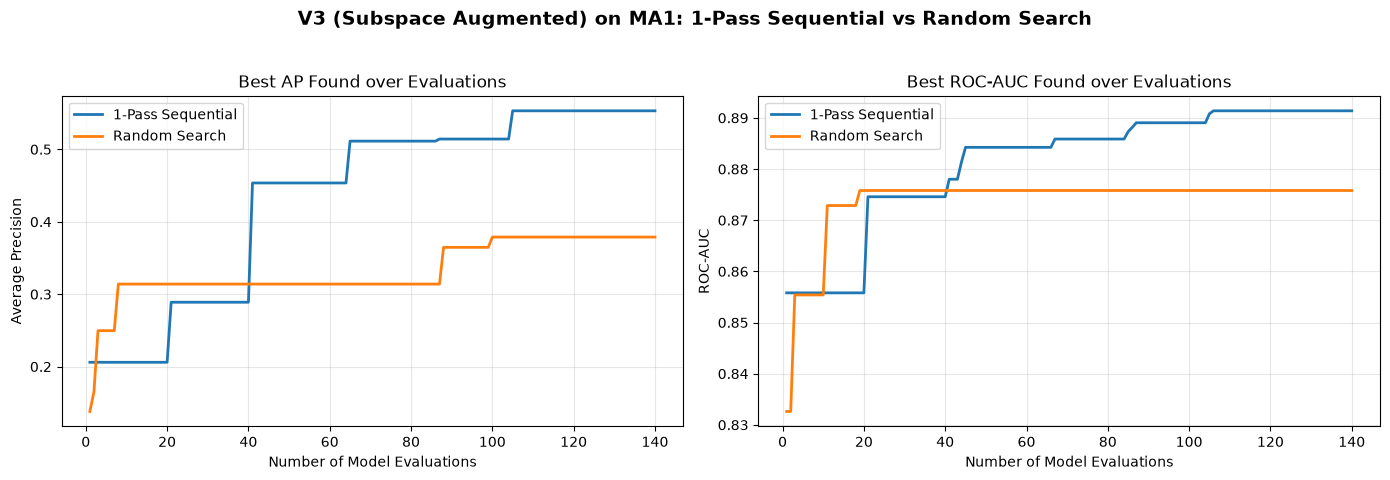


--------------------------------------------------------------------------------
Comparing 1-Pass Sequential vs Random Search: V3 (Subspace Augmented) on MA2
Total Computation Budget: 140 evaluations per method
--------------------------------------------------------------------------------
Sequential | Time: 497.43s | Max AP: 0.1404 | Max ROC: 0.7917
Random     | Time: 290.52s | Max AP: 0.1249 | Max ROC: 0.7668


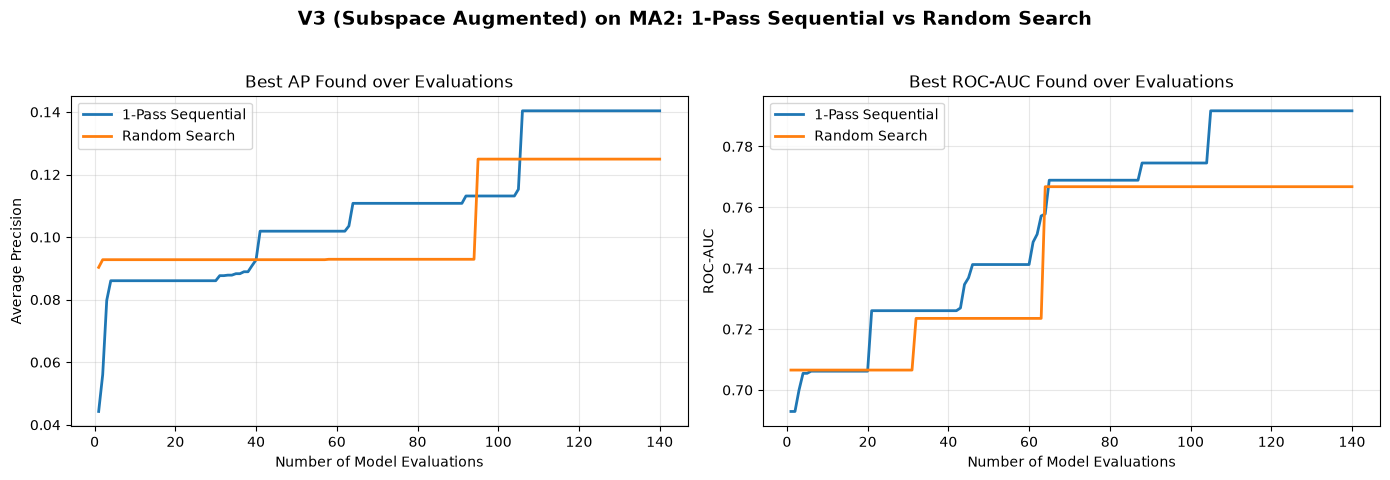


--------------------------------------------------------------------------------
Comparing 1-Pass Sequential vs Random Search: V3 (Subspace Augmented) on MA3
Total Computation Budget: 140 evaluations per method
--------------------------------------------------------------------------------
Sequential | Time: 333.85s | Max AP: 0.3770 | Max ROC: 0.7836
Random     | Time: 195.28s | Max AP: 0.3562 | Max ROC: 0.7793


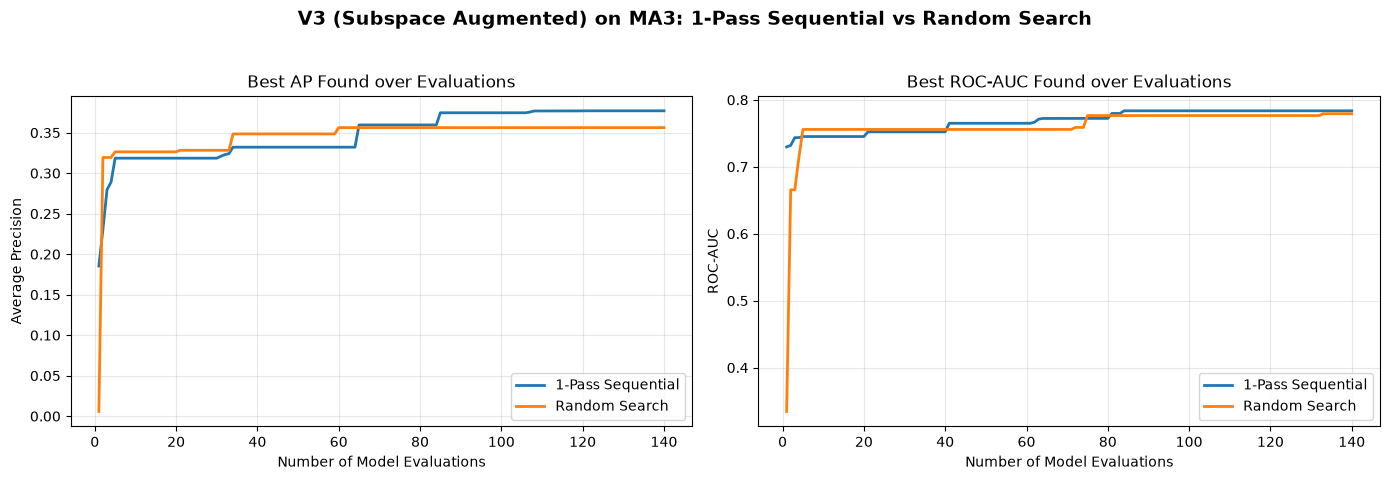

In [29]:
# Cell 20
# Execution for V3 (Subspace Augmented)
var_name = "V3 (Subspace Augmented)"
for name, X_tem in [('MA1', X_tem_ma1), ('MA2', X_tem_ma2), ('MA3', X_tem_ma3)]:
    s_ap, s_roc, r_ap, r_roc = comparative_search(X, y, X_tem, name, var_name)
    plot_comparison(s_ap, s_roc, r_ap, r_roc, var_name, name)

#### ⚪ V4


--------------------------------------------------------------------------------
Comparing 1-Pass Sequential vs Random Search: V4 (Tiered Evidence NDF) on MA1
Total Computation Budget: 120 evaluations per method
--------------------------------------------------------------------------------
Sequential | Time: 530.10s | Max AP: 0.5645 | Max ROC: 0.9191
Random     | Time: 265.09s | Max AP: 0.4248 | Max ROC: 0.8963


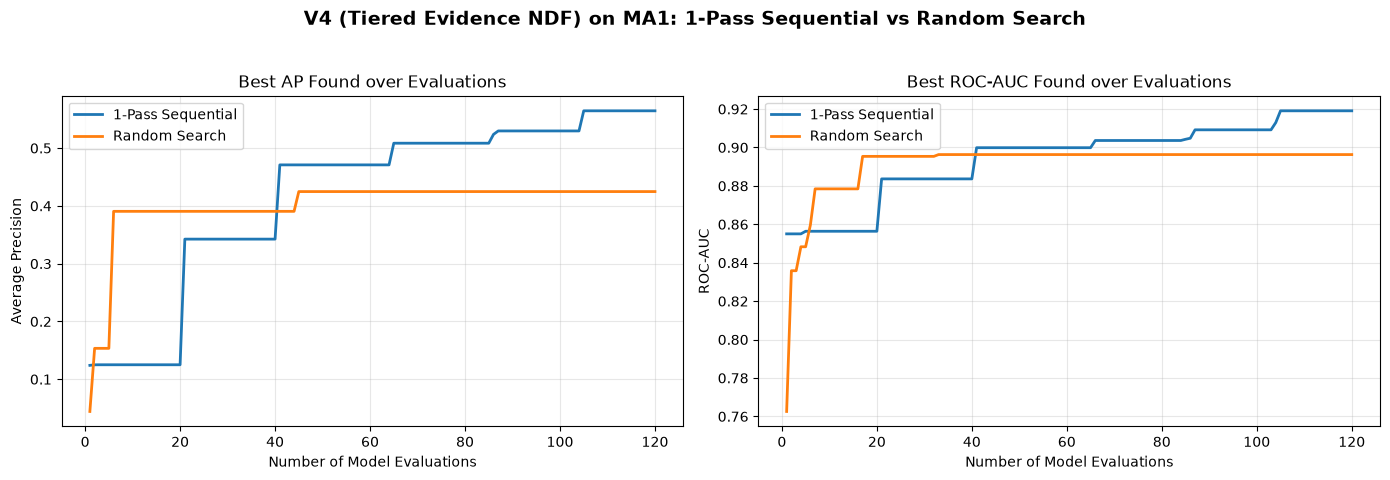


--------------------------------------------------------------------------------
Comparing 1-Pass Sequential vs Random Search: V4 (Tiered Evidence NDF) on MA2
Total Computation Budget: 120 evaluations per method
--------------------------------------------------------------------------------
Sequential | Time: 452.10s | Max AP: 0.0679 | Max ROC: 0.8141
Random     | Time: 226.30s | Max AP: 0.1372 | Max ROC: 0.8051


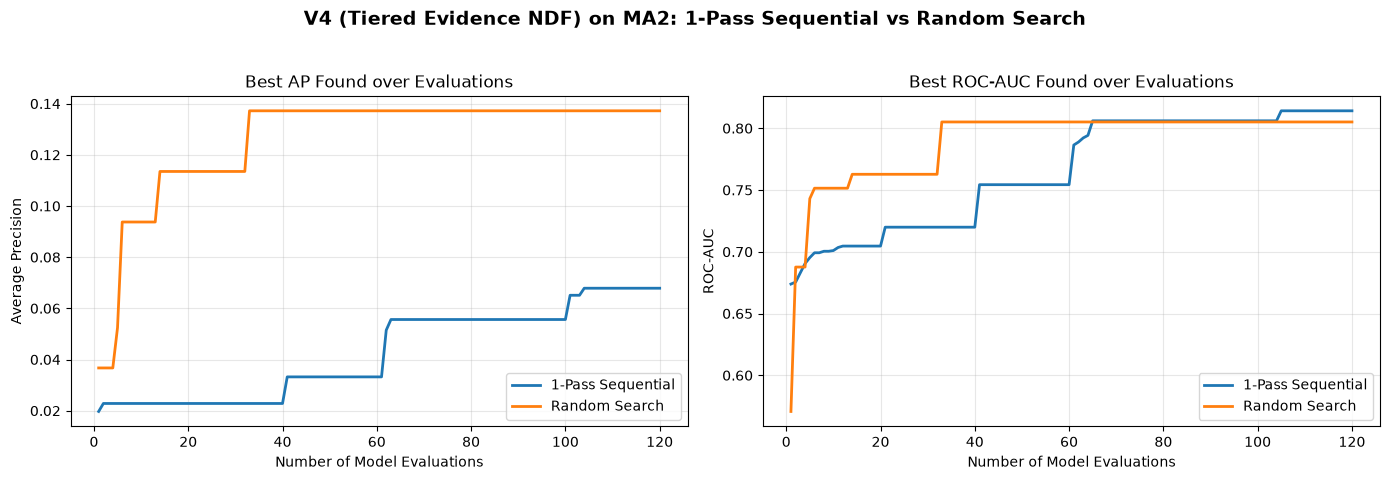


--------------------------------------------------------------------------------
Comparing 1-Pass Sequential vs Random Search: V4 (Tiered Evidence NDF) on MA3
Total Computation Budget: 120 evaluations per method
--------------------------------------------------------------------------------
Sequential | Time: 305.13s | Max AP: 0.4124 | Max ROC: 0.7656
Random     | Time: 154.43s | Max AP: 0.3550 | Max ROC: 0.8521


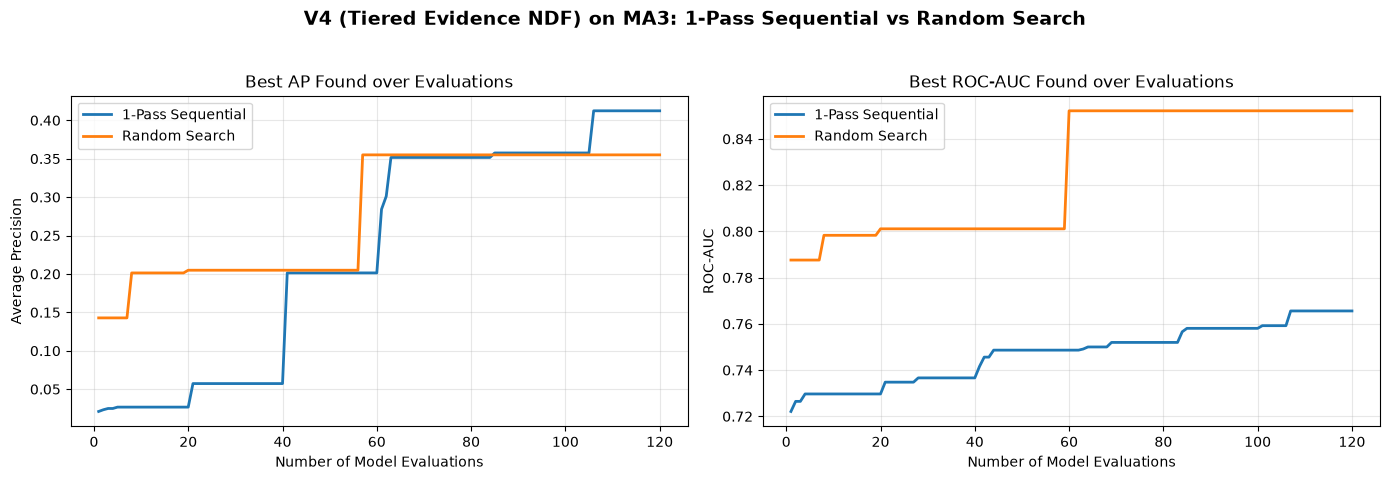

In [30]:
# Cell 21
# Execution for V4 (Tiered Evidence NDF)
var_name = "V4 (Tiered Evidence NDF)"
for name, X_tem in [('MA1', X_tem_ma1), ('MA2', X_tem_ma2), ('MA3', X_tem_ma3)]:
    s_ap, s_roc, r_ap, r_roc = comparative_search(X, y, X_tem, name, var_name)
    plot_comparison(s_ap, s_roc, r_ap, r_roc, var_name, name)

#### ⚪ V5


--------------------------------------------------------------------------------
Comparing 1-Pass Sequential vs Random Search: V5 (Robust Scale Only) on MA1
Total Computation Budget: 120 evaluations per method
--------------------------------------------------------------------------------
Sequential | Time: 593.97s | Max AP: 0.0443 | Max ROC: 0.7948
Random     | Time: 305.10s | Max AP: 0.0510 | Max ROC: 0.7945


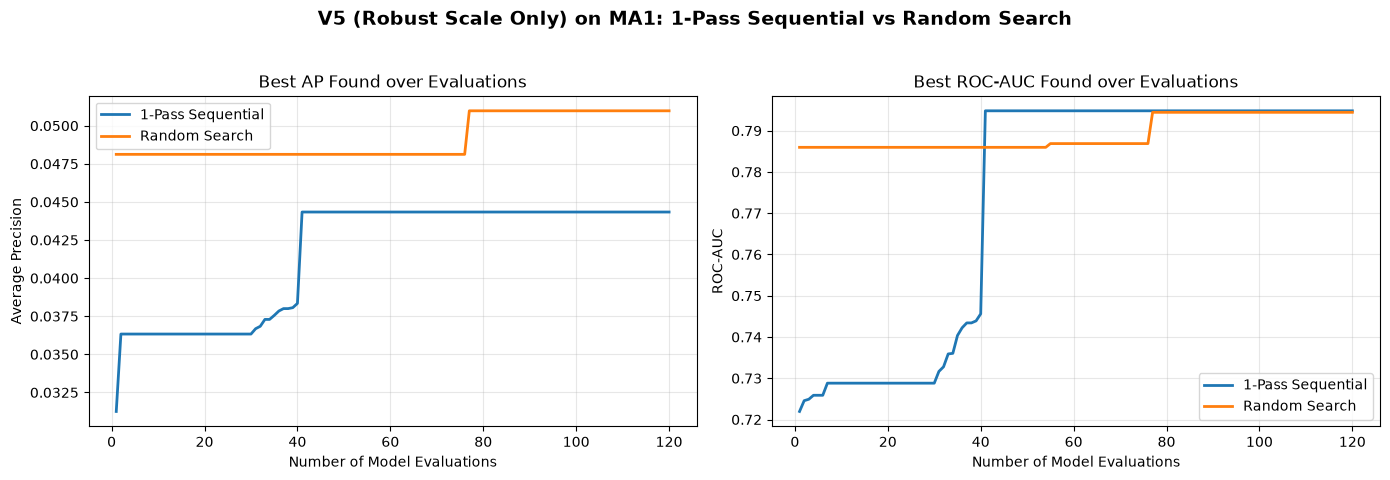


--------------------------------------------------------------------------------
Comparing 1-Pass Sequential vs Random Search: V5 (Robust Scale Only) on MA2
Total Computation Budget: 120 evaluations per method
--------------------------------------------------------------------------------
Sequential | Time: 515.35s | Max AP: 0.0841 | Max ROC: 0.7159
Random     | Time: 257.75s | Max AP: 0.0819 | Max ROC: 0.7107


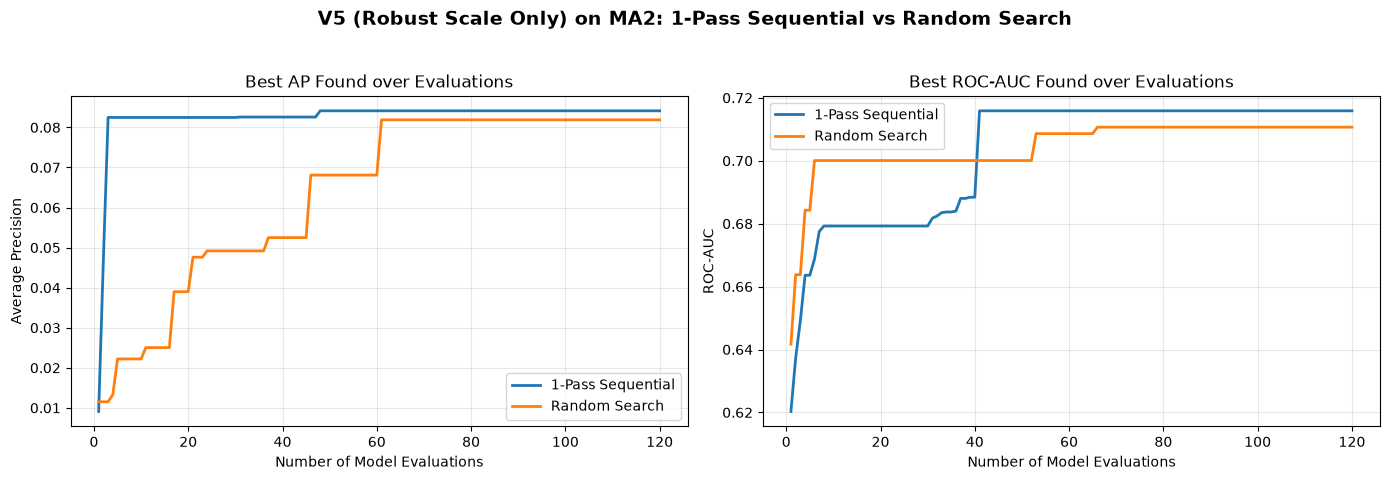


--------------------------------------------------------------------------------
Comparing 1-Pass Sequential vs Random Search: V5 (Robust Scale Only) on MA3
Total Computation Budget: 120 evaluations per method
--------------------------------------------------------------------------------
Sequential | Time: 348.50s | Max AP: 0.1627 | Max ROC: 0.7961
Random     | Time: 175.45s | Max AP: 0.1589 | Max ROC: 0.7883


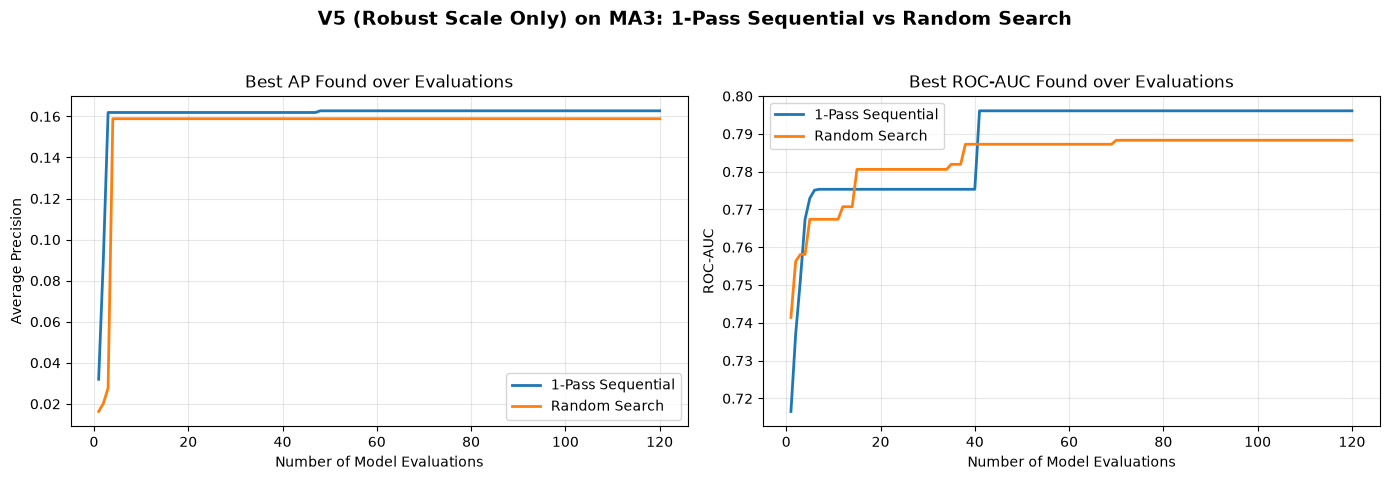

In [31]:
# Cell 22
# Execution for V5 (Robust Scale Only)
var_name = "V5 (Robust Scale Only)"
for name, X_tem in [('MA1', X_tem_ma1), ('MA2', X_tem_ma2), ('MA3', X_tem_ma3)]:
    s_ap, s_roc, r_ap, r_roc = comparative_search(X, y, X_tem, name, var_name)
    plot_comparison(s_ap, s_roc, r_ap, r_roc, var_name, name)

#### ⚪ V6


--------------------------------------------------------------------------------
Comparing 1-Pass Sequential vs Random Search: V6 (Silverman Selector Only) on MA1
Total Computation Budget: 120 evaluations per method
--------------------------------------------------------------------------------
Sequential | Time: 609.71s | Max AP: 0.1137 | Max ROC: 0.8660
Random     | Time: 305.62s | Max AP: 0.0930 | Max ROC: 0.8542


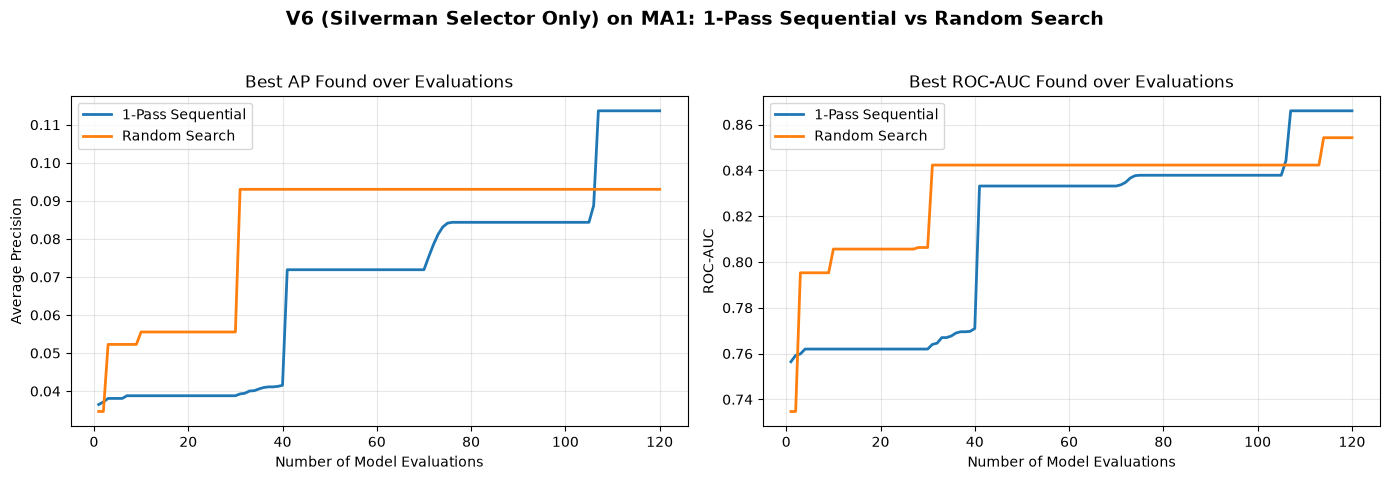


--------------------------------------------------------------------------------
Comparing 1-Pass Sequential vs Random Search: V6 (Silverman Selector Only) on MA2
Total Computation Budget: 120 evaluations per method
--------------------------------------------------------------------------------
Sequential | Time: 518.24s | Max AP: 0.1461 | Max ROC: 0.8070
Random     | Time: 257.73s | Max AP: 0.1259 | Max ROC: 0.7464


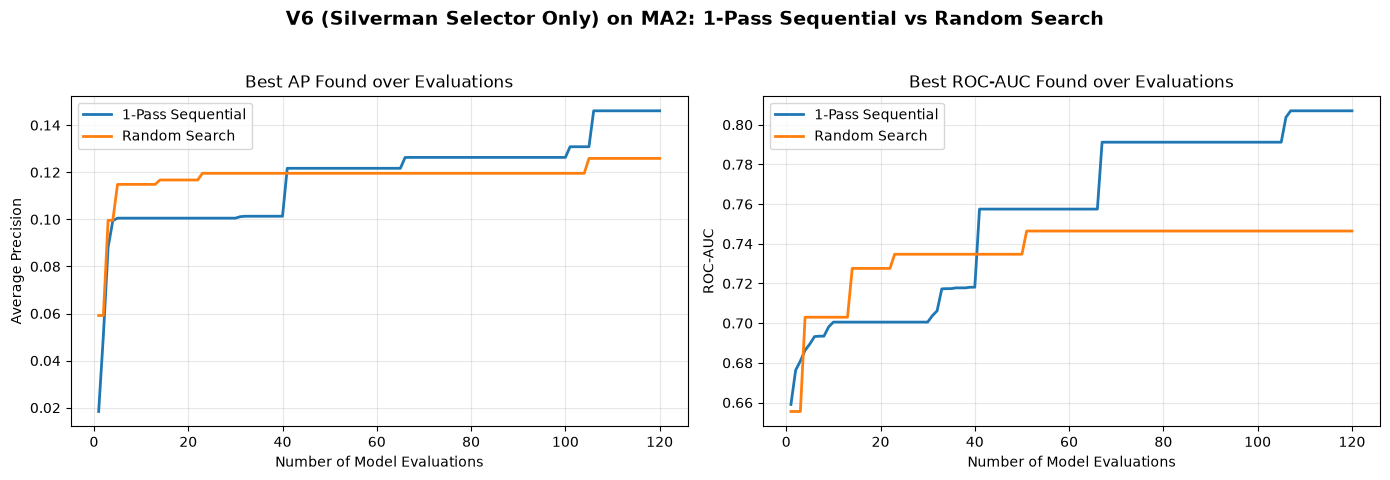


--------------------------------------------------------------------------------
Comparing 1-Pass Sequential vs Random Search: V6 (Silverman Selector Only) on MA3
Total Computation Budget: 120 evaluations per method
--------------------------------------------------------------------------------
Sequential | Time: 347.07s | Max AP: 0.2291 | Max ROC: 0.8394
Random     | Time: 172.76s | Max AP: 0.2210 | Max ROC: 0.8240


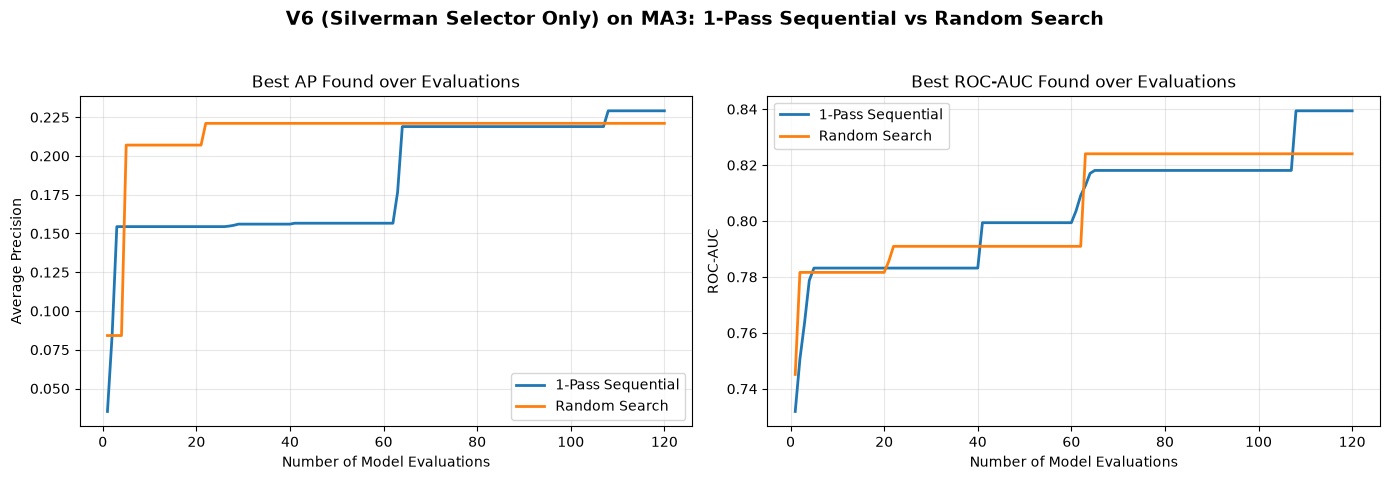

In [32]:
# Cell 23
# Execution for V6 (Silverman Selector Only)
var_name = "V6 (Silverman Selector Only)"
for name, X_tem in [('MA1', X_tem_ma1), ('MA2', X_tem_ma2), ('MA3', X_tem_ma3)]:
    s_ap, s_roc, r_ap, r_roc = comparative_search(X, y, X_tem, name, var_name)
    plot_comparison(s_ap, s_roc, r_ap, r_roc, var_name, name)

#### ⚪ V8


--------------------------------------------------------------------------------
Comparing 1-Pass Sequential vs Random Search: V8 (Resolution Floor Only) on MA1
Total Computation Budget: 120 evaluations per method
--------------------------------------------------------------------------------
Sequential | Time: 618.60s | Max AP: 0.5645 | Max ROC: 0.9191
Random     | Time: 304.66s | Max AP: 0.3877 | Max ROC: 0.8804


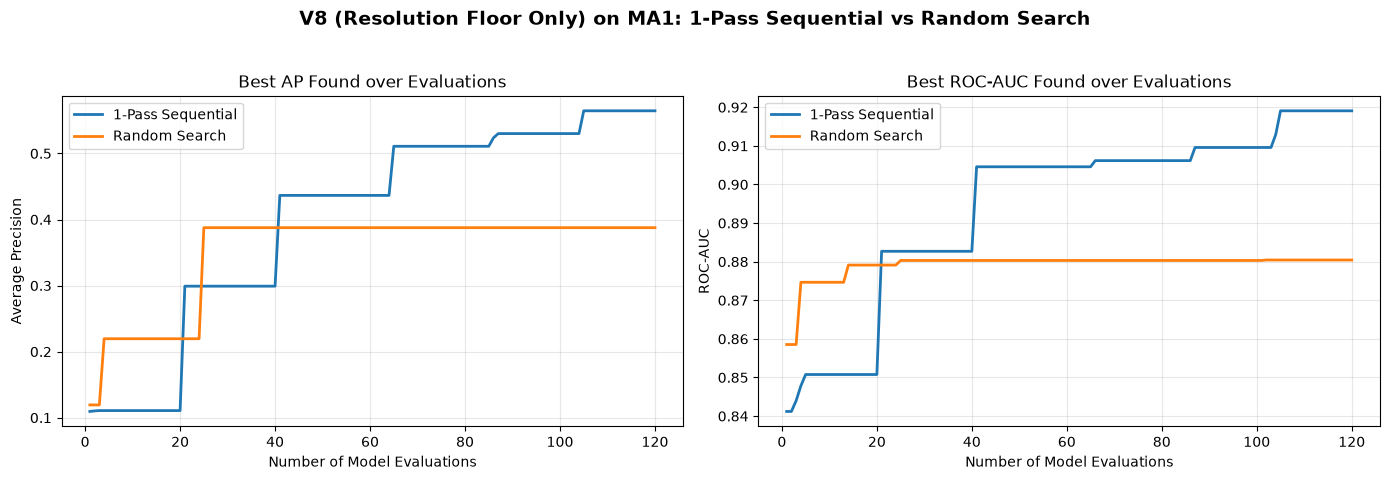


--------------------------------------------------------------------------------
Comparing 1-Pass Sequential vs Random Search: V8 (Resolution Floor Only) on MA2
Total Computation Budget: 120 evaluations per method
--------------------------------------------------------------------------------
Sequential | Time: 515.82s | Max AP: 0.1220 | Max ROC: 0.8322
Random     | Time: 248.48s | Max AP: 0.1176 | Max ROC: 0.7868


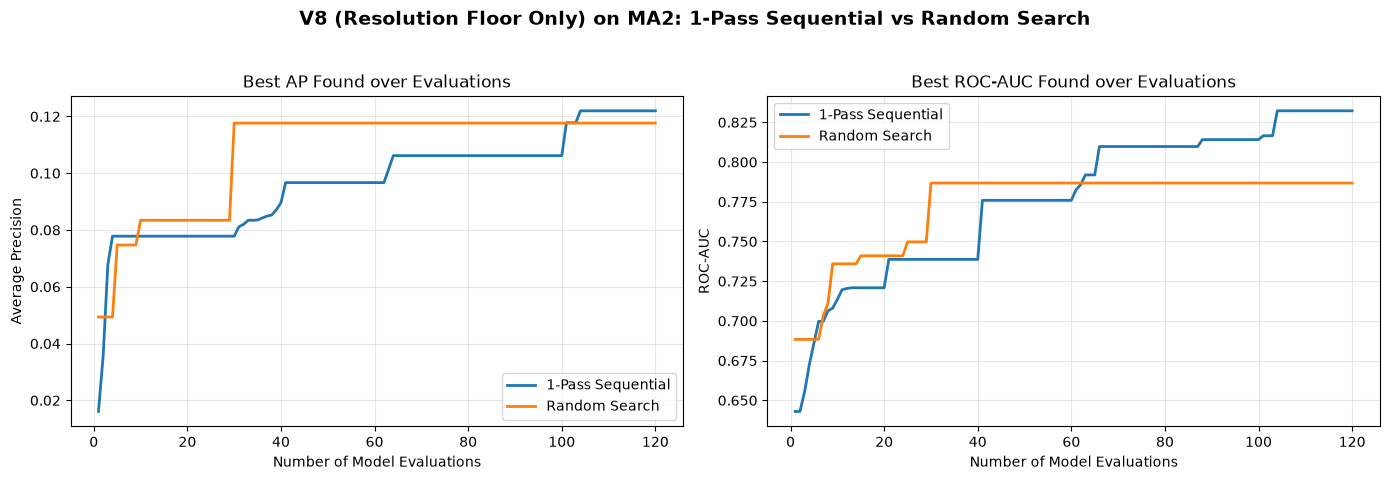


--------------------------------------------------------------------------------
Comparing 1-Pass Sequential vs Random Search: V8 (Resolution Floor Only) on MA3
Total Computation Budget: 120 evaluations per method
--------------------------------------------------------------------------------
Sequential | Time: 335.35s | Max AP: 0.3184 | Max ROC: 0.7988
Random     | Time: 167.86s | Max AP: 0.2853 | Max ROC: 0.7912


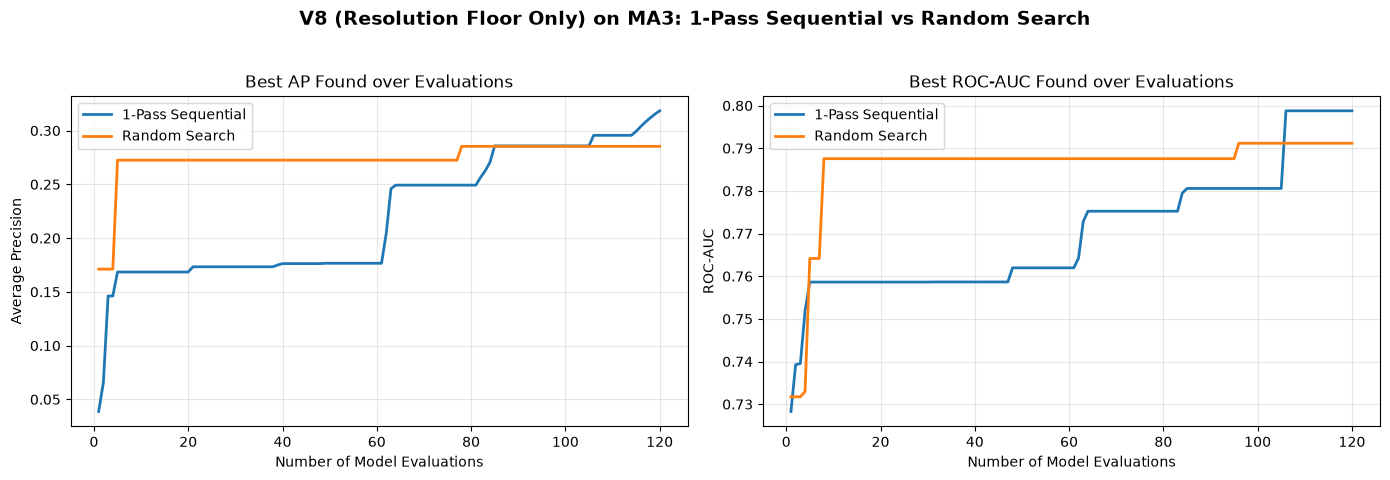

In [33]:
# Cell 24
# Execution for V8 (Resolution Floor Only)
var_name = "V8 (Resolution Floor Only)"
for name, X_tem in [('MA1', X_tem_ma1), ('MA2', X_tem_ma2), ('MA3', X_tem_ma3)]:
    s_ap, s_roc, r_ap, r_roc = comparative_search(X, y, X_tem, name, var_name)
    plot_comparison(s_ap, s_roc, r_ap, r_roc, var_name, name)

#### End